<a href="https://colab.research.google.com/github/annabellemeyer2-prog/ML441-Assignment4/blob/main/27129160RW441assignment4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 4: Ensemble Learning (Option 1)

## Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import time
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             cohen_kappa_score, matthews_corrcoef,
                             confusion_matrix, classification_report)

DATA_PATH = '/content/drive/MyDrive/Stellenbosch/Machine learning/Assignment 2/'
OUT_PATH = '/content/drive/MyDrive/Stellenbosch/Machine learning/Assignment 4/'
os.makedirs(OUT_PATH, exist_ok=True)

SEED = 42
N_FOLDS = 10
TUNE_SAMPLE_SIZE = 30000
TUNE_VAL_FRACTION = 0.3
RERUN_BASELINES = False

In [ ]:
import pickle

def cached(filename, compute_fn, rerun=False):
    path = OUT_PATH + filename
    if os.path.exists(path) and not rerun:
        with open(path, 'rb') as fh:
            result = pickle.load(fh)
        print(f"Loaded saved result: {filename}")
        return result
    t0 = time.time()
    result = compute_fn()
    with open(path, 'wb') as fh:
        pickle.dump(result, fh)
    print(f"Computed and saved: {filename} ({time.time() - t0:.0f}s)")
    return result

In [ ]:
raw = pd.read_csv(DATA_PATH + 'networkTraffic.csv')
attack_map = pd.read_csv(DATA_PATH + 'attack_category_map.csv')
attack_names = attack_map.set_index('Mapping')['Attack Category Name']

print(raw.shape)
raw.head()

(257673, 44)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat
0,1,0.000011,udp,?,INT,2,0,496,0,90909.0902,...,1,1,2,0,0,0,1,2,0,0
1,2,0.000008,udp,?,INT,2,0,1762,0,125000.0003,...,1,1,2,0,0,0,1,2,0,0
2,3,0.000005,udp,?,INT,2,0,1068,0,200000.0051,...,1,1,3,0,0,0,1,3,0,0
3,4,0.000006,udp,?,INT,2,0,900,0,166666.6608,...,2,1,3,0,0,0,2,3,0,0
4,5,0.000010,udp,?,INT,2,0,2126,0,100000.0025,...,2,1,3,0,0,0,2,3,0,0


## Data Quality Evidence

All checks read from the raw dataframe without adding columns to it.

In [ ]:
missing_pct = (raw == '?').mean() * 100
print("Features with missing values (pct):")
print(missing_pct[missing_pct > 0].round(2))

service_missing = raw['service'] == '?'
print("\nPct of service missing within each state value:")
print(pd.crosstab(raw['state'], service_missing, normalize='index').mul(100).round(1))
print("\nPct of service missing within the six most common proto values:")
top_proto_values = raw['proto'].value_counts().head(6).index
print(pd.crosstab(raw.loc[raw['proto'].isin(top_proto_values), 'proto'],
                  service_missing[raw['proto'].isin(top_proto_values)],
                  normalize='index').mul(100).round(1))

Features with missing values (pct):
service    54.85
dtype: float64

Pct of service missing within each state value:
service  False  True 
state                
ACC       25.0   75.0
CLO        0.0  100.0
CON       53.9   46.1
ECO        0.0  100.0
FIN       40.4   59.6
INT       49.7   50.3
PAR        0.0  100.0
REQ        6.1   93.9
RST       16.7   83.3
URN        0.0  100.0
no         0.0  100.0

Pct of service missing within the six most common proto values:
service  False  True 
proto                
arp        0.0  100.0
ospf       0.0  100.0
sctp       0.0  100.0
tcp       38.6   61.4
udp       74.3   25.7
unas       0.0  100.0


In [ ]:
class_counts = raw['attack_cat'].value_counts()
class_summary = pd.DataFrame({
    'name': [attack_names.get(c, 'Unknown') for c in class_counts.index],
    'count': class_counts.values,
    'pct': (class_counts.values / len(raw) * 100).round(2)
}, index=class_counts.index)
class_summary

,name,count,pct
attack_cat,,,
0,Normal,93000,36.09
9,Generic,58871,22.85
4,Exploits,44525,17.28
6,Fuzzers,24246,9.41
3,DoS,16353,6.35
1,Reconnaissance,13987,5.43
5,Analysis,2677,1.04
2,Backdoor,2329,0.90
8,Shellcode,1511,0.59


In [ ]:
for col in ['proto', 'state', 'service']:
    print(f"{col}: {raw[col].nunique()} distinct values")

print("\nis_ftp_login value counts:")
print(raw['is_ftp_login'].value_counts().sort_index())

print("\nid unique for every row:", raw['id'].nunique() == len(raw))

proto: 133 distinct values
state: 11 distinct values
service: 13 distinct values

is_ftp_login value counts:
is_ftp_login
0    254428
1      3219
2        10
4        16
Name: count, dtype: int64

id unique for every row: True


In [ ]:
numeric_features = raw.columns.drop(['id', 'proto', 'state', 'service', 'attack_cat'])

corr_matrix = raw[numeric_features].corr()
corr_pairs = corr_matrix.where(~np.tril(np.ones(corr_matrix.shape)).astype(bool)).stack().reset_index()
corr_pairs.columns = ['feature_1', 'feature_2', 'correlation']
corr_pairs['abs_correlation'] = corr_pairs['correlation'].abs()
strong_corr = corr_pairs[corr_pairs['abs_correlation'] > 0.9].sort_values('abs_correlation', ascending=False)
strong_corr

,feature_1,feature_2,correlation,abs_correlation
726,is_ftp_login,ct_ftp_cmd,0.998855,0.998855
152,dbytes,dloss,0.996711,0.996711
117,sbytes,sloss,0.995772,0.995772
490,swin,dwin,0.980458,0.980458
83,dpkts,dloss,0.979612,0.979612
684,ct_srv_src,ct_srv_dst,0.979467,0.979467
76,dpkts,dbytes,0.973445,0.973445
46,spkts,sloss,0.971859,0.971859
39,spkts,sbytes,0.964393,0.964393
696,ct_dst_ltm,ct_src_dport_ltm,0.961518,0.961518


In [ ]:
outlier_check = pd.DataFrame({
    'min': raw[numeric_features].min(),
    'q1': raw[numeric_features].quantile(0.25),
    'median': raw[numeric_features].median(),
    'q3': raw[numeric_features].quantile(0.75),
    'max': raw[numeric_features].max()
})
outlier_check['high_ratio'] = (outlier_check['max'] - outlier_check['q3']) / \
                              (outlier_check['q3'] - outlier_check['median']).replace(0, np.nan)
outlier_check['low_ratio'] = (outlier_check['q1'] - outlier_check['min']) / \
                             (outlier_check['median'] - outlier_check['q1']).replace(0, np.nan)
outlier_check['range'] = outlier_check['max'] - outlier_check['min']
outlier_check.sort_values('high_ratio', ascending=False)

,min,q1,median,q3,max,high_ratio,low_ratio,range
sbytes,24.0,114.000000,528.000000,1.362000e+03,1.435577e+07,17211.525180,0.217391,1.435575e+07
dbytes,0.0,0.000000,178.000000,1.064000e+03,1.465753e+07,16542.287810,0.000000,1.465753e+07
djit,0.0,0.000000,0.000000,1.197129e+02,4.631992e+05,3868.249654,NaN,4.631992e+05
dloss,0.0,0.000000,0.000000,2.000000e+00,5.507000e+03,2752.500000,NaN,5.507000e+03
sloss,0.0,0.000000,0.000000,3.000000e+00,5.319000e+03,1772.000000,NaN,5.319000e+03
sinpkt,0.0,0.008000,0.381696,5.809473e+01,8.437150e+04,1460.907525,0.021408,8.437150e+04
dpkts,0.0,0.000000,2.000000,1.000000e+01,1.101800e+04,1376.000000,0.000000,1.101800e+04
spkts,1.0,2.000000,4.000000,1.200000e+01,1.064600e+04,1329.250000,0.500000,1.064500e+04
dload,0.0,0.000000,1747.441284,2.210538e+04,2.242273e+07,1100.338285,0.000000,2.242273e+07
dinpkt,0.0,0.000000,0.007000,5.643886e+01,5.773924e+04,1022.167303,0.000000,5.773924e+04


**Observations:**

- **Missing values:** only `service` has missing values (`?`), in 54.85% of rows. Missingness follows `proto` and `state`: arp, ospf, sctp and unas are 100% missing, tcp 61.4% and udp 25.7%. State REQ is 93.9% missing. Missingness is explained by other features (MAR), as in Assignment 2, so "missing" is kept as its own category rather than imputed.
- **Class skew:** Normal 36.09% (93 000 rows) down to Worms 0.07% (174 rows). Four classes sit under 1.1%: Analysis 1.04%, Backdoor 0.90%, Shellcode 0.59%, Worms 0.07%.
- **Cardinality:** proto 133 values, state 11, service 13 (including `?`). Most proto values are rare; the top five covered 92.54% of rows in Assignment 2.
- **Invalid values:** `is_ftp_login` is binary but has 10 rows with value 2 and 16 rows with value 4.
- **id:** unique for every row, so no predictive information.
- **Correlations:** 18 pairs with |r| > 0.9. Strongest: is_ftp_login/ct_ftp_cmd 0.9989, dbytes/dloss 0.9967, sbytes/sloss 0.9958.
- **Outliers (gap comparison):** the gap from Q3 to max is far larger than the gap from median to Q3. sbytes 17 212 times, dbytes 16 542, djit 3 868, dloss 2 753. Ten features have a ratio above 1 000. Several features have Q3 = median = 0 (trans_depth, response_body_len, ct_flw_http_mthd), so the ratio is undefined for them.
- **Ranges:** sload reaches 5.99e9 and stcpb/dtcpb reach 4.29e9, while binary features sit in [0, 1].
- **stcpb / dtcpb:** median 0 and Q3 around 2e9. These are TCP base sequence numbers. Flagged for a relevance check in Decision C.

## Preprocessing Pipelines

Both pipelines branch from the raw dataframe through functions, so rerunning a cell never stacks transformations. Steps shared by both models sit in one cleaning function. Steps specific to kNN or the tree sit in separate functions.

SMOTE is not included. Assignment 2 rejected SMOTE for both models on ten fold cross validation evidence.

In [ ]:
TOP_PROTOS = raw['proto'].value_counts().head(5).index.tolist()
KEEP_STATES = ['FIN', 'INT', 'CON', 'REQ', 'RST']
KNN_DROP_CORRELATED = [
    'sloss', 'spkts',
    'dloss', 'dpkts',
    'is_sm_ips_ports',
    'synack', 'ackdat',
    'ct_srv_src', 'ct_dst_src_ltm',
    'ct_dst_sport_ltm', 'ct_dst_ltm', 'ct_src_ltm',
    'ct_ftp_cmd'
]

def base_cleaning(df_raw):
    df = df_raw.copy()
    df = df.drop(columns=['id'])
    df['service'] = df['service'].replace('?', 'missing')
    df['is_ftp_login'] = df['is_ftp_login'].replace({2: 0, 4: 0})
    df['proto'] = df['proto'].where(df['proto'].isin(TOP_PROTOS), 'other')
    df['state'] = df['state'].where(df['state'].isin(KEEP_STATES), 'other')
    return df

def prepare_knn(df_raw):
    df = base_cleaning(df_raw)
    df = df.drop(columns=KNN_DROP_CORRELATED)
    df = pd.get_dummies(df, columns=['proto', 'state', 'service'],
                        prefix=['proto', 'state', 'service'], dtype=int)
    X = df.drop(columns=['attack_cat'])
    y = df['attack_cat'].values
    return X, y

def prepare_tree(df_raw):
    df = base_cleaning(df_raw)
    df['service_is_missing'] = (df['service'] == 'missing').astype(int)
    encoder = OrdinalEncoder()
    df[['proto', 'state', 'service']] = encoder.fit_transform(df[['proto', 'state', 'service']])
    X = df.drop(columns=['attack_cat'])
    y = df['attack_cat'].values
    return X, y

In [ ]:
X_knn, y_knn = prepare_knn(raw)
X_tree, y_tree = prepare_tree(raw)

print("kNN shape:", X_knn.shape, "| duplicate columns:", X_knn.columns.duplicated().any())
print("Tree shape:", X_tree.shape, "| duplicate columns:", X_tree.columns.duplicated().any())
print("Same target order:", np.array_equal(y_knn, y_tree))
print("\nkNN columns:", X_knn.columns.tolist())
print("\nTree columns:", X_tree.columns.tolist())

kNN shape: (257673, 51) | duplicate columns: False
Tree shape: (257673, 43) | duplicate columns: False
Same target order: True

kNN columns: ['dur', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_state_ttl', 'ct_src_dport_ltm', 'is_ftp_login', 'ct_flw_http_mthd', 'ct_srv_dst', 'proto_arp', 'proto_ospf', 'proto_other', 'proto_tcp', 'proto_udp', 'proto_unas', 'state_CON', 'state_FIN', 'state_INT', 'state_REQ', 'state_RST', 'state_other', 'service_dhcp', 'service_dns', 'service_ftp', 'service_ftp-data', 'service_http', 'service_irc', 'service_missing', 'service_pop3', 'service_radius', 'service_smtp', 'service_snmp', 'service_ssh', 'service_ssl']

Tree columns: ['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', '

## Fold Assignment

One stratified ten fold split is created and saved. Every model in Assignment 4, including the ensemble, uses these exact folds, which keeps the paired Wilcoxon comparison valid.

In [ ]:
y_all = raw['attack_cat'].values
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

fold_id = np.zeros(len(raw), dtype=int)
for f, (_, test_idx) in enumerate(skf.split(np.zeros(len(y_all)), y_all), 1):
    fold_id[test_idx] = f

pd.Series(fold_id, name='fold').to_csv(OUT_PATH + 'fold_assignment.csv', index=False)

fold_class_counts = pd.crosstab(fold_id, y_all)
fold_class_counts.columns = [attack_names.get(c, c) for c in fold_class_counts.columns]
fold_class_counts

,Normal,Reconnaissance,Backdoor,DoS,Exploits,Analysis,Fuzzers,Worms,Shellcode,Generic
row_0,,,,,,,,,,
1,9300,1399,233,1635,4453,268,2424,18,151,5887
2,9300,1399,233,1635,4453,267,2425,17,152,5887
3,9300,1399,233,1635,4453,267,2425,17,151,5888
4,9300,1399,233,1635,4453,267,2425,17,151,5887
5,9300,1399,233,1635,4452,268,2425,17,151,5887
6,9300,1399,233,1635,4452,268,2425,17,151,5887
7,9300,1399,232,1636,4452,268,2425,17,151,5887
8,9300,1398,233,1636,4452,268,2424,18,151,5887
9,9300,1398,233,1636,4452,268,2424,18,151,5887


## Evaluation Framework

Within each outer fold, control parameters are tuned on the training portion only. A stratified subsample of the training portion is split into a tuning train set and a validation set. The parameter set with the highest validation macro F1 is refit on the full training portion and evaluated on the held out fold. The test fold never influences parameter selection.

In [ ]:
def compute_metrics(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'macro_recall': recall_score(y_true, y_pred, average='macro'),
        'kappa': cohen_kappa_score(y_true, y_pred),
        'mcc': matthews_corrcoef(y_true, y_pred),
    }

def tune_on_training_fold(X_train, y_train, param_grid, make_model, scale, fold_seed):
    X_sub, _, y_sub, _ = train_test_split(
        X_train, y_train, train_size=TUNE_SAMPLE_SIZE, stratify=y_train, random_state=fold_seed)
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_sub, y_sub, test_size=TUNE_VAL_FRACTION, stratify=y_sub, random_state=fold_seed)

    if scale:
        scaler = MinMaxScaler()
        X_tr = scaler.fit_transform(X_tr)
        X_val = scaler.transform(X_val)

    val_scores = []
    for params in param_grid:
        model = make_model(**params)
        model.fit(X_tr, y_tr)
        val_scores.append(f1_score(y_val, model.predict(X_val), average='macro'))

    best_params = param_grid[int(np.argmax(val_scores))]
    log = pd.DataFrame({'params': [str(p) for p in param_grid], 'val_macro_f1': val_scores})
    return best_params, log

In [ ]:
def run_cv(model_label, X, y, fold_id, param_grid, make_model, scale=False, train_metrics=True):
    X = np.asarray(X, dtype=float)
    fold_rows = []
    tuning_logs = []
    oof_pred = np.empty(len(y), dtype=y.dtype)

    for f in range(1, N_FOLDS + 1):
        start = time.time()
        test_mask = fold_id == f
        X_train, X_test = X[~test_mask], X[test_mask]
        y_train, y_test = y[~test_mask], y[test_mask]

        best_params, log = tune_on_training_fold(
            X_train, y_train, param_grid, make_model, scale, SEED + f)
        log['fold'] = f
        tuning_logs.append(log)

        if scale:
            scaler = MinMaxScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)

        model = make_model(**best_params)
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        oof_pred[test_mask] = preds

        row = {'model': model_label, 'fold': f, **compute_metrics(y_test, preds)}
        if train_metrics:
            row['train_accuracy'] = accuracy_score(y_train, model.predict(X_train))
        row['params'] = str(best_params)
        row['seconds'] = round(time.time() - start, 1)
        fold_rows.append(row)

        print(f"Fold {f}: params={best_params}, accuracy={row['accuracy']:.4f}, "
              f"macro F1={row['macro_f1']:.4f}, kappa={row['kappa']:.4f}, "
              f"MCC={row['mcc']:.4f}, time={row['seconds']}s")

    return pd.DataFrame(fold_rows), oof_pred, pd.concat(tuning_logs, ignore_index=True)

def pop_std(s):
    return s.std(ddof=0)

def summarise(results):
    metric_cols = [c for c in ['train_accuracy', 'accuracy', 'macro_f1', 'macro_recall', 'kappa', 'mcc']
                   if c in results.columns]
    return results.groupby('model')[metric_cols].agg(['mean', pop_std]).round(4)

## Baseline 1: k Nearest Neighbours

In [ ]:
knn_grid = [{'n_neighbors': k} for k in [3, 5, 7, 9, 11, 15, 21]]

def make_knn(**params):
    return KNeighborsClassifier(n_jobs=-1, **params)

if RERUN_BASELINES:
    knn_results, knn_oof, knn_tuning = run_cv(
        'kNN', X_knn, y_knn, fold_id, knn_grid, make_knn, scale=True)
    knn_results.to_csv(OUT_PATH + 'knn_fold_results.csv', index=False)
    knn_tuning.to_csv(OUT_PATH + 'knn_tuning_log.csv', index=False)
else:
    saved_oof = pd.read_csv(OUT_PATH + 'baseline_oof_predictions.csv')
    print("Folds match saved run:", np.array_equal(saved_oof['fold'].values, fold_id))
    print("Targets match saved run:", np.array_equal(saved_oof['y_true'].values, y_all))
    knn_results = pd.read_csv(OUT_PATH + 'knn_fold_results.csv')
    knn_tuning = pd.read_csv(OUT_PATH + 'knn_tuning_log.csv')
    knn_oof = saved_oof['knn_pred'].values

summarise(knn_results)

Folds match saved run: True
Targets match saved run: True


train_accuracy         accuracy         macro_f1         macro_recall  \
                mean pop_std     mean pop_std     mean pop_std         mean   
model                                                                         
kNN           0.8085  0.0065   0.7671  0.0055   0.4705  0.0113       0.4537   

                kappa             mcc          
      pop_std    mean pop_std    mean pop_std  
model                                          
kNN    0.0078  0.6951  0.0064  0.6962  0.0064

## Baseline 2: Classification Tree

In [ ]:
tree_grid = [{'max_depth': d, 'min_samples_leaf': l}
             for d in [5, 10, 15, 20, None]
             for l in [1, 5, 20, 50]]

def make_tree(**params):
    return DecisionTreeClassifier(criterion='entropy', random_state=SEED, **params)

if RERUN_BASELINES:
    tree_results, tree_oof, tree_tuning = run_cv(
        'Tree', X_tree, y_tree, fold_id, tree_grid, make_tree, scale=False)
    tree_results.to_csv(OUT_PATH + 'tree_fold_results.csv', index=False)
    tree_tuning.to_csv(OUT_PATH + 'tree_tuning_log.csv', index=False)
else:
    tree_results = pd.read_csv(OUT_PATH + 'tree_fold_results.csv')
    tree_tuning = pd.read_csv(OUT_PATH + 'tree_tuning_log.csv')
    tree_oof = pd.read_csv(OUT_PATH + 'baseline_oof_predictions.csv')['tree_pred'].values

summarise(tree_results)

train_accuracy         accuracy         macro_f1         macro_recall  \
                mean pop_std     mean pop_std     mean pop_std         mean   
model                                                                         
Tree          0.8635  0.0285   0.8155  0.0045   0.5693  0.0368       0.5536   

                kappa             mcc          
      pop_std    mean pop_std    mean pop_std  
model                                          
Tree   0.0369  0.7578  0.0064  0.7602  0.0056

In [ ]:
all_results = pd.concat([knn_results, tree_results], ignore_index=True)
all_results.to_csv(OUT_PATH + 'baseline_fold_results.csv', index=False)

print(summarise(all_results))
print("\nSelected parameters per fold:")
print(all_results.pivot(index='fold', columns='model', values='params'))

      train_accuracy         accuracy         macro_f1         macro_recall  \
                mean pop_std     mean pop_std     mean pop_std         mean   
model                                                                         
Tree          0.8635  0.0285   0.8155  0.0045   0.5693  0.0368       0.5536   
kNN           0.8085  0.0065   0.7671  0.0055   0.4705  0.0113       0.4537   

                kappa             mcc          
      pop_std    mean pop_std    mean pop_std  
model                                          
Tree   0.0369  0.7578  0.0064  0.7602  0.0056  
kNN    0.0078  0.6951  0.0064  0.6962  0.0064  

Selected parameters per fold:
model                                        Tree                 kNN
fold                                                                 
1        {'max_depth': 20, 'min_samples_leaf': 1}  {'n_neighbors': 9}
2      {'max_depth': None, 'min_samples_leaf': 5}  {'n_neighbors': 7}
3        {'max_depth': 10, 'min_samples_leaf': 1}  {'

**Observations:**

- **Compared with Assignment 2:** kNN macro F1 0.4705 (A2: 0.4690), accuracy 0.7671 (A2: 0.7696). Tree macro F1 0.5693 (A2: 0.5836), accuracy 0.8155 (A2: 0.8187). kNN barely moved. The tree dropped, which fits with A2 tuning on a subsample that overlapped the test folds. The fixed parameter check in Decision A shows tuning noise also contributes.
- **Stability of selected parameters:** the tree picked six different configurations in 10 folds. kNN picked four different k values (3, 5, 7, 9).
- **Train versus test gap:** tree 0.8635 vs 0.8155 (gap 0.048), with train accuracy ranging from 0.809 to 0.915 depending on the configuration picked. kNN 0.8085 vs 0.7671 (gap 0.041).
- **Fold to fold spread:** macro F1 std is 0.0368 for the tree vs 0.0113 for kNN. Accuracy std is lower for the tree (0.0045 vs 0.0055), so the instability of the tree shows up in macro F1, which is driven by the rare classes, not in overall accuracy.
- **Runtime:** kNN 495 to 545 s per fold, tree 18 to 22 s per fold.

## Per Class Behaviour

In [ ]:
class_labels = [attack_names.get(c, str(c)) for c in sorted(np.unique(y_all))]

for label, oof in [('kNN', knn_oof), ('Tree', tree_oof)]:
    print(f"===== {label} =====")
    cm = pd.DataFrame(confusion_matrix(y_all, oof), index=class_labels, columns=class_labels)
    print(cm)
    print()
    print(classification_report(y_all, oof, target_names=class_labels, digits=3))

pd.DataFrame({'fold': fold_id, 'y_true': y_all, 'knn_pred': knn_oof, 'tree_pred': tree_oof}) \
  .to_csv(OUT_PATH + 'baseline_oof_predictions.csv', index=False)

===== kNN =====
                Normal  Reconnaissance  Backdoor   DoS  Exploits  Analysis  \
Normal           85130            1027         4   112       801        92   
Reconnaissance    1310            9085        56  1249      2033         1   
Backdoor            79             191       133   926       919        18   
DoS                679             818       362  7203      6802        44   
Exploits          2581            2291       761  9059     28521       104   
Analysis           378              64       185   927       943       140   
Fuzzers          10389             890       376  1062      1884        30   
Worms               10              13         0     3       115         0   
Shellcode          289             504         0    40        70         0   
Generic            156              80        11   323       782         0   

                Fuzzers  Worms  Shellcode  Generic  
Normal             5766      2         52       14  
Reconnaissance     

**Observations:**

- **Tree better in 9 of 10 classes on F1.** The exception is DoS: kNN 0.387 vs tree 0.298.
- **DoS / Exploits confusion:** the tree predicts 11 412 of 16 353 DoS rows (69.8%) as Exploits, with DoS recall of 0.257. kNN predicts more rows as DoS (recall 0.440) but sends 9 059 Exploits rows to DoS. The two models fail on this pair in opposite directions.
- **Fuzzers / Normal confusion:** the tree predicts 7 920 Fuzzers rows (32.7%) as Normal and 5 132 Normal rows as Fuzzers. kNN is worse: 10 389 and 5 766.
- **Backdoor and Analysis:** tree recall is only 0.092 and 0.074, even though precision is 0.682 and 0.567. Most rows from both classes go to Exploits: 1 501 of 2 329 Backdoor (64.4%) and 1 570 of 2 677 Analysis (58.6%).
- **Worms:** tree recall 0.477 vs kNN 0.092. Shellcode: tree 0.610 vs kNN 0.322.
- **Generic is almost perfect for both** (F1 0.988 and 0.986).
- These are the classes to watch with the random forest. If they do not improve, that supports slide 25 (bagging does not reduce bias).

## Statistical Comparison: kNN versus Classification Tree

A paired Wilcoxon signed rank test compares the two models fold by fold on each metric.

In [ ]:
for metric in ['accuracy', 'macro_f1', 'macro_recall', 'kappa', 'mcc']:
    stat, p = wilcoxon(knn_results[metric], tree_results[metric])
    tree_wins = (tree_results[metric].values > knn_results[metric].values).sum()
    print(f"{metric}: statistic={stat:.1f}, p={p:.4f}, tree better in {tree_wins}/10 folds")

accuracy: statistic=0.0, p=0.0020, tree better in 10/10 folds
macro_f1: statistic=1.0, p=0.0039, tree better in 9/10 folds
macro_recall: statistic=1.0, p=0.0039, tree better in 9/10 folds
kappa: statistic=0.0, p=0.0020, tree better in 10/10 folds
mcc: statistic=0.0, p=0.0020, tree better in 10/10 folds


**Observations:**

- Tree better in 10/10 folds on accuracy, kappa and MCC (statistic 0, p = 0.0020).
- Tree better in 9/10 folds on macro F1 and macro recall (statistic 1, p = 0.0039).
- The one fold kNN wins on macro F1 is fold 3 (0.4930 vs 0.4734), the fold where tuning picked max_depth = 10. With fixed parameters the tree scores 0.5975 to 0.6011 in fold 3, well above kNN.
- With 10 folds, 0.0020 is the smallest p-value possible, so the result is as strong as this test can show.
- Five metrics are tested on the same folds, and they are strongly related. Mention multiple comparisons in the report.

## Runtime Check for Ensemble Planning

A single fully grown tree is timed on one training fold, once considering all features at each split and once considering the square root of the number of features.

In [ ]:
X_tree_np = X_tree.values.astype(float)
train_mask = fold_id != 1

for max_feat in [None, 'sqrt']:
    t0 = time.time()
    DecisionTreeClassifier(criterion='entropy', max_depth=None, min_samples_leaf=1,
                           max_features=max_feat, random_state=SEED) \
        .fit(X_tree_np[train_mask], y_tree[train_mask])
    print(f"max_features={max_feat}: {time.time() - t0:.1f} seconds for one tree")

max_features=None: 10.8 seconds for one tree
max_features=sqrt: 1.9 seconds for one tree


**Observations:**

- One fully grown tree on one training fold: 9.0 s with all features, 1.3 s with sqrt features. An earlier session gave 10.4 s and 1.5 s, so timings vary between sessions by about 13%.
- The fixed parameter tree runs took 8.2 to 10.4 s per fold, including the tuning fit.
- Rough random forest cost per final fit is the number of trees × 1.3 s, divided by the number of cores used. Tuning fits use 21 000 rows instead of about 231 900, so they are much cheaper per tree.
- Example: 100 trees take about 130 s per final fit on one core, before tuning. Time a small run before fixing the grid.

## Decision A: Tuning Protocol

The cells below gather evidence on how reliable the validation signal inside each training fold is.

In [ ]:
val_class_counts = []
for f in range(1, N_FOLDS + 1):
    y_train_f = y_all[fold_id != f]
    idx = np.arange(len(y_train_f))
    idx_sub, _, y_sub, _ = train_test_split(
        idx, y_train_f, train_size=TUNE_SAMPLE_SIZE, stratify=y_train_f, random_state=SEED + f)
    _, _, _, y_val = train_test_split(
        idx_sub, y_sub, test_size=TUNE_VAL_FRACTION, stratify=y_sub, random_state=SEED + f)
    val_class_counts.append(pd.Series(y_val).value_counts().sort_index().rename(f))

val_class_counts = pd.DataFrame(val_class_counts)
val_class_counts.columns = [attack_names.get(c, c) for c in val_class_counts.columns]
val_class_counts.index.name = 'fold'
val_class_counts.to_csv(OUT_PATH + 'validation_class_counts.csv')
val_class_counts

,Normal,Reconnaissance,Backdoor,DoS,Exploits,Analysis,Fuzzers,Worms,Shellcode,Generic
fold,,,,,,,,,,
1,3249,488,81,571,1555,94,847,6,53,2056
2,3249,488,81,571,1555,94,847,6,53,2056
3,3249,488,81,571,1555,94,847,6,53,2056
4,3249,488,81,571,1555,94,847,6,53,2056
5,3249,488,81,571,1555,94,847,6,53,2056
6,3249,488,81,571,1555,94,847,6,53,2056
7,3249,488,81,571,1555,94,847,6,53,2056
8,3249,488,81,571,1555,94,847,6,53,2056
9,3249,488,81,571,1555,94,847,6,53,2056


In [ ]:
tree_tuning_log = pd.read_csv(OUT_PATH + 'tree_tuning_log.csv')
tree_fold_res = pd.read_csv(OUT_PATH + 'tree_fold_results.csv')

noise_rows = []
for f in range(1, N_FOLDS + 1):
    log_f = tree_tuning_log[tree_tuning_log['fold'] == f].sort_values('val_macro_f1', ascending=False)
    best_val = log_f['val_macro_f1'].iloc[0]
    test_f1 = tree_fold_res.loc[tree_fold_res['fold'] == f, 'macro_f1'].iloc[0]
    noise_rows.append({
        'fold': f,
        'selected_params': tree_fold_res.loc[tree_fold_res['fold'] == f, 'params'].iloc[0],
        'best_val_macro_f1': round(best_val, 4),
        'gap_to_second_best': round(best_val - log_f['val_macro_f1'].iloc[1], 4),
        'configs_within_0.01': int((log_f['val_macro_f1'] >= best_val - 0.01).sum()),
        'test_macro_f1': round(test_f1, 4),
        'val_minus_test': round(best_val - test_f1, 4),
    })

tuning_noise = pd.DataFrame(noise_rows)
tuning_noise.to_csv(OUT_PATH + 'tree_tuning_noise.csv', index=False)
tuning_noise

,fold,selected_params,best_val_macro_f1,gap_to_second_best,configs_within_0.01,test_macro_f1,val_minus_test
0,1,"{'max_depth': 20, 'min_samples_leaf': 1}",0.5382,0.0055,2,0.5737,-0.0355
1,2,"{'max_depth': None, 'min_samples_leaf': 5}",0.5606,0.0001,2,0.6057,-0.0451
2,3,"{'max_depth': 10, 'min_samples_leaf': 1}",0.5369,0.0004,5,0.4734,0.0635
3,4,"{'max_depth': None, 'min_samples_leaf': 5}",0.5331,0.0012,3,0.5573,-0.0242
4,5,"{'max_depth': None, 'min_samples_leaf': 5}",0.5451,0.0025,4,0.6074,-0.0623
5,6,"{'max_depth': 20, 'min_samples_leaf': 1}",0.5438,0.0001,6,0.5734,-0.0296
6,7,"{'max_depth': 15, 'min_samples_leaf': 5}",0.4946,0.0038,6,0.5527,-0.0581
7,8,"{'max_depth': None, 'min_samples_leaf': 1}",0.5192,0.0014,3,0.6019,-0.0827
8,9,"{'max_depth': 15, 'min_samples_leaf': 1}",0.5626,0.0143,1,0.5742,-0.0117
9,10,"{'max_depth': 20, 'min_samples_leaf': 5}",0.5578,0.0022,3,0.5733,-0.0156


## Fixed Parameter Tree Diagnostic

The tuned tree selects six different control parameter combinations across the 10 folds. The fixed parameter runs below hold the control parameters constant in every fold, which removes tuning noise from the fold to fold variation. Two configurations each appear three times in the tuning results, so both run: max_depth=None with min_samples_leaf=5, and max_depth=20 with min_samples_leaf=1.

In [ ]:
fixed_configs = {
    'Tree fixed (None, 5)': {'max_depth': None, 'min_samples_leaf': 5},
    'Tree fixed (20, 1)': {'max_depth': 20, 'min_samples_leaf': 1},
}

fixed_results = []
for label, params in fixed_configs.items():
    print(f"===== {label} =====")
    res, _, _ = run_cv(label, X_tree, y_tree, fold_id, [params], make_tree, scale=False)
    fixed_results.append(res)

tree_variance_check = pd.concat([tree_fold_res] + fixed_results, ignore_index=True)
tree_variance_check.to_csv(OUT_PATH + 'tree_variance_check.csv', index=False)

print(summarise(tree_variance_check))
print("\nMacro F1 per fold:")
print(tree_variance_check.pivot(index='fold', columns='model', values='macro_f1').round(4))

===== Tree fixed (None, 5) =====
Fold 1: params={'max_depth': None, 'min_samples_leaf': 5}, accuracy=0.8126, macro F1=0.5701, kappa=0.7555, MCC=0.7563, time=8.8s
Fold 2: params={'max_depth': None, 'min_samples_leaf': 5}, accuracy=0.8099, macro F1=0.6057, kappa=0.7521, MCC=0.7527, time=9.3s
Fold 3: params={'max_depth': None, 'min_samples_leaf': 5}, accuracy=0.8141, macro F1=0.6011, kappa=0.7574, MCC=0.7582, time=9.5s
Fold 4: params={'max_depth': None, 'min_samples_leaf': 5}, accuracy=0.8123, macro F1=0.5573, kappa=0.7552, MCC=0.7560, time=10.0s
Fold 5: params={'max_depth': None, 'min_samples_leaf': 5}, accuracy=0.8149, macro F1=0.6074, kappa=0.7582, MCC=0.7591, time=8.6s
Fold 6: params={'max_depth': None, 'min_samples_leaf': 5}, accuracy=0.8141, macro F1=0.5918, kappa=0.7573, MCC=0.7582, time=9.4s
Fold 7: params={'max_depth': None, 'min_samples_leaf': 5}, accuracy=0.8133, macro F1=0.5792, kappa=0.7564, MCC=0.7575, time=8.5s
Fold 8: params={'max_depth': None, 'min_samples_leaf': 5}, accu

**Observations:**

- **Validation set composition:** identical in every fold. Out of 9 000 rows: Worms 6, Shellcode 53, Backdoor 81, Analysis 94.
- **Close calls:** the gap between the best and second best configuration is at most 0.0055 in 9 of 10 folds, and at most 0.0025 in 7 of 10. At least two configurations sit within 0.01 of the winner in 9 of 10 folds, and at least three in 7 of 10.
- **Fold 3:** five configurations within 0.01, with a gap to second best of only 0.0004. The winner (depth 10) scored 0.5369 on validation but 0.4734 on test, the only fold where validation overestimated test (+0.0635).
- **Validation underestimates test in the other 9 folds** (val minus test between -0.0827 and -0.0117). Tuning models train on 21 000 rows, the final models on about 231 900.
- **Fixed parameters:** macro F1 std drops from 0.0368 to 0.0132 (depth 20, leaf 1) and 0.0171 (no depth limit, leaf 5). Mean macro F1 rises from 0.5693 to 0.5813 and 0.5890. Fold 3 rises from 0.4734 to 0.5975 and 0.6011.
- **Compared with kNN:** fixed tree macro F1 std (0.0132 to 0.0171) is only slightly above kNN (0.0113). Fixed tree accuracy std (0.0013 to 0.0014) is well below kNN (0.0055).
- **Caveat:** the two fixed configurations were picked by counting selections across all 10 folds, so they use information from every fold. They are a diagnostic only, not a valid baseline for the final comparison.

### Decision A

**Evidence**

- Each validation set holds 6 Worms, 53 Shellcode, 81 Backdoor and 94 Analysis rows out of 9 000. Macro F1 weights every class equally, so a few rare class predictions shift the validation score.
- The best and second best tree configurations differ by at most 0.0055 in 9 of 10 folds. At least three configurations sit within 0.01 of the winner in 7 of 10 folds.
- Fold 3: tuning picked depth 10 (validation 0.5369, gap to second best 0.0004), which scored 0.4734 on test, the lowest tree score across folds.
- Fixed parameters cut the tree macro F1 std from 0.0368 to between 0.0132 and 0.0171, and raise the mean from 0.5693 to between 0.5813 and 0.5890.

**Justification**

- The protocol is kept for all three models.
- Cawley and Talbot showed that a noisy model selection criterion causes over-fitting in model selection, with losses comparable to differences between learning algorithms. The fixed parameter check confirms this for the tree (0.012 to 0.020 macro F1 lost).
- Tuning the random forest on out of bag error (about 231 900 rows) while the baselines use 9 000 validation rows would give the random forest a better selection signal, mixing the effect of bagging with the effect of better tuning.
- Out of bag error is used only as a diagnostic for the number of trees (slide 33).
- The fixed parameter trees are reported next to the tuned tree as a diagnostic reference, so the gap between the random forest and the tree can be read with the tuning noise in mind.

## Evidence for Decision B: Sensitivity to the Training Data

The fixed parameter check showed that most of the fold to fold spread of the tuned tree came from tuning noise, so the spread across folds is not strong evidence of variance. Slide 24 describes variance as sensitivity to small fluctuations in the training set. The check below measures that directly: 10 fully grown trees (the random forest base learner from slide 30) are trained on different bootstrap samples, and their predictions on the same rows are compared.

The check uses only the training portion of fold 1, split 70/30, so no test fold influences the choice of ensemble method.

A second check looks for identical feature rows with different labels. A fully grown tree only reached 0.915 train accuracy in fold 8, which suggests some rows cannot be separated by any tree.




In [ ]:
from scipy.stats import mode

X_tree_np = X_tree.values.astype(float)
tr_mask = fold_id != 1
X_fit, X_chk, y_fit, y_chk = train_test_split(
    X_tree_np[tr_mask], y_tree[tr_mask], test_size=0.3,
    stratify=y_tree[tr_mask], random_state=SEED)

N_BOOT = 10
rng = np.random.RandomState(SEED)
boot_preds, boot_f1 = [], []
for b in range(N_BOOT):
    idx = rng.randint(0, len(y_fit), len(y_fit))
    t = DecisionTreeClassifier(criterion='entropy', random_state=SEED + b)
    t.fit(X_fit[idx], y_fit[idx])
    p = t.predict(X_chk)
    boot_preds.append(p)
    boot_f1.append(f1_score(y_chk, p, average='macro'))

boot_preds = np.array(boot_preds)
unanimous = (boot_preds == boot_preds[0]).all(axis=0)
vote = mode(boot_preds, axis=0, keepdims=False).mode

print(f"Rows where the {N_BOOT} trees do not all agree: {(~unanimous).mean():.4f}")
print(f"Single tree macro F1: mean {np.mean(boot_f1):.4f}, std {np.std(boot_f1):.4f}, "
      f"range {min(boot_f1):.4f} to {max(boot_f1):.4f}")
print(f"Majority vote macro F1: {f1_score(y_chk, vote, average='macro'):.4f}")

disagree_by_class = pd.Series(~unanimous).groupby(y_chk).mean().round(4)
disagree_by_class.index = [attack_names.get(c, c) for c in disagree_by_class.index]
print("\nDisagreement rate per true class:")
print(disagree_by_class.sort_values(ascending=False))

Rows where the 10 trees do not all agree: 0.3737
Single tree macro F1: mean 0.5573, std 0.0035, range 0.5516 to 0.5624
Majority vote macro F1: 0.5999

Disagreement rate per true class:
Worms             0.9574
Backdoor          0.8776
Analysis          0.8672
Shellcode         0.8480
DoS               0.8328
Fuzzers           0.7946
Exploits          0.6536
Reconnaissance    0.2995
Normal            0.2454
Generic           0.0252
dtype: float64


In [ ]:
row_key = pd.util.hash_pandas_object(X_tree, index=False).values
dup = pd.DataFrame({'key': row_key, 'y': y_tree})

n_labels = dup.groupby('key')['y'].transform('nunique')
conflict = (n_labels > 1).values
max_acc = dup.groupby(['key', 'y']).size().groupby(level=0).max().sum() / len(dup)

print(f"Rows that duplicate an earlier row: {pd.Series(row_key).duplicated().sum()}")
print(f"Rows whose feature vector appears with more than one label: {conflict.sum()} ({conflict.mean():.4f})")
print(f"Highest accuracy any model could reach on the full dataset: {max_acc:.4f}")

conflict_by_class = pd.Series(conflict).groupby(y_tree).mean().round(4)
conflict_by_class.index = [attack_names.get(c, c) for c in conflict_by_class.index]
print("\nShare of rows with conflicting labels per class:")
print(conflict_by_class.sort_values(ascending=False))

Rows that duplicate an earlier row: 104255
Rows whose feature vector appears with more than one label: 40402 (0.1568)
Highest accuracy any model could reach on the full dataset: 0.9136

Share of rows with conflicting labels per class:
Backdoor          0.8489
DoS               0.7744
Analysis          0.7699
Exploits          0.3707
Reconnaissance    0.1606
Fuzzers           0.1492
Worms             0.0862
Normal            0.0100
Shellcode         0.0086
Generic           0.0063
dtype: float64


**Observations:**

**Bootstrap variance check (fold 1 training portion, 70/30 split):**
- The 10 bootstrap trees do not all agree on 37.37% of rows.
- Single tree macro F1: mean 0.5573, std 0.0035, range 0.5516 to 0.5624. Majority vote macro F1: 0.5999, which is +0.0426 over the mean single tree and +0.0375 over the best single tree.
- The trees reach almost identical macro F1 but make different errors, which is what voting removes.
- Disagreement per class: Worms 95.7%, Backdoor 87.8%, Analysis 86.7%, Shellcode 84.8%, DoS 83.3%, Fuzzers 79.5%, Exploits 65.4%, Reconnaissance 30.0%, Normal 24.5%, Generic 2.5%.

**Duplicate rows with conflicting labels:**
- 104 255 rows (40.5%) duplicate an earlier row exactly.
- 40 402 rows (15.68%) belong to feature vectors that appear with more than one label.
- Highest achievable accuracy on the full dataset: 0.9136. This matches the train accuracy of the fully grown tree in fold 8 (0.9148).
- Conflict rate per class: Backdoor 84.9%, DoS 77.4%, Analysis 77.0%, Exploits 37.1%, Reconnaissance 16.1%, Fuzzers 14.9%, Worms 8.6%, Normal 1.0%, Shellcode 0.9%, Generic 0.6%.

**Together:**
- Backdoor, DoS and Analysis have high disagreement AND high conflict, so a large part of their error cannot be removed by any model using these features.
- Worms, Shellcode and Fuzzers have high disagreement but low conflict, so their errors come mainly from variance, which bagging targets.

## Decision B: Choice of Ensemble Method

**Evidence**

- Train versus test gap: tuned tree 0.8635 vs 0.8155. Fixed trees 0.8807 vs 0.8128 (no depth limit, leaf 5) and 0.8690 vs 0.8189 (depth 20, leaf 1).
- Fold to fold spread is mostly tuning noise (fixed tree macro F1 std 0.0132 to 0.0171 vs 0.0113 for kNN), so spread across folds is not used as evidence of variance.
- Sensitivity to the training data: 10 fully grown trees on different bootstrap samples disagree on 37.37% of rows. Disagreement reaches 95.7% for Worms and 84.8% for Shellcode.
- Voting the 10 trees raises macro F1 from 0.5573 (mean single tree) to 0.5999.
- 15.68% of rows have identical features but different labels, concentrated in Backdoor (84.9%), DoS (77.4%) and Analysis (77.0%). Highest achievable accuracy is 0.9136.
- One tree with sqrt features trains in 1.3 s on a full training fold.

**Justification**

- **Random forest selected.** Slide 24: bagging reduces sensitivity to small fluctuations in the training set. The bootstrap check shows the tree is highly sensitive (37.37% disagreement), and even a plain vote over 10 bootstrap trees gains 0.0426 macro F1. Slide 31: trees overfit, which is desirable for bagging, and the train versus test gap confirms the overfitting.
- **Similar comparison.** Same entropy tree and same `prepare_tree` features as the Assignment 2 tree, so differences reflect bagging and subspace sampling (slide 29), not a different model type. Slide 33 lists the control parameters for the tuning questions. Handles all 10 classes directly, and 1.3 s per tree makes a grid feasible.
- **Alternatives rejected.** Extra trees (slides 37 and 38) suit very many features and do slightly worse with noisy features; 43 features with extreme outliers give no reason to prefer them. AdaBoost (slide 56, examples on slides 58 and 59) is binary only on the slides, and slide 24 places its strength in reducing bias, while the evidence points to variance. Stacking (slides 22 and 23) needs out of sample kNN predictions in every training fold, at 495 to 546 s per fold for kNN alone.
- **Expectation.** Slide 25: bagging does not reduce bias. The conflicting labels set a hard limit for Backdoor, DoS and Analysis. The forest is expected to

## Decision C: Data Transformations for the Random Forest

### Duplicate rows and leakage across folds

40.5% of rows duplicate an earlier row. Tavallaee et al. found that duplicates in KDD CUP 99 biased both learning and evaluation, and removed them. The check below tests whether duplicates inflate the scores here, using the saved out of fold predictions: every test row is marked as seen (an identical feature row exists in the training folds) or unseen.

In [ ]:
row_key = pd.util.hash_pandas_object(X_tree, index=False).values

seen = np.zeros(len(y_all), dtype=bool)
for f in range(1, N_FOLDS + 1):
    te = fold_id == f
    seen[te] = np.isin(row_key[te], row_key[~te])

print(f"Test rows with an identical copy in the training folds: {seen.mean():.4f}")

rows = []
for label, oof in [('kNN', knn_oof), ('Tree', tree_oof)]:
    for name, mask in [('all', np.ones_like(seen)), ('seen', seen), ('unseen', ~seen)]:
        rows.append({'model': label, 'subset': name, 'rows': int(mask.sum()),
                     'accuracy': round(accuracy_score(y_all[mask], oof[mask]), 4),
                     'macro_f1': round(f1_score(y_all[mask], oof[mask], average='macro'), 4)})
print(pd.DataFrame(rows))

seen_by_class = pd.Series(seen).groupby(y_all).mean().round(4)
seen_by_class.index = [attack_names.get(c, c) for c in seen_by_class.index]
print("\nShare of test rows already seen in training, per class:")
print(seen_by_class.sort_values(ascending=False))

Test rows with an identical copy in the training folds: 0.4586
  model  subset    rows  accuracy  macro_f1
0   kNN     all  257673    0.7671    0.4722
1   kNN    seen  118179    0.7609    0.5156
2   kNN  unseen  139494    0.7722    0.4305
3  Tree     all  257673    0.8155    0.5752
4  Tree    seen  118179    0.7782    0.5116
5  Tree  unseen  139494    0.8471    0.6477

Share of test rows already seen in training, per class:
Generic           0.9666
Analysis          0.8648
Backdoor          0.8506
DoS               0.7807
Exploits          0.4729
Reconnaissance    0.4258
Fuzzers           0.2721
Normal            0.1128
Worms             0.0805
Shellcode         0.0675
dtype: float64


In [ ]:
per_class = []
for c in sorted(np.unique(y_all)):
    in_c = y_all == c
    for label, oof in [('kNN', knn_oof), ('Tree', tree_oof)]:
        s, u = in_c & seen, in_c & ~seen
        per_class.append({'class': attack_names.get(c, c), 'model': label,
                          'recall_seen': round((oof[s] == c).mean(), 3) if s.any() else np.nan,
                          'recall_unseen': round((oof[u] == c).mean(), 3) if u.any() else np.nan})
pd.DataFrame(per_class).pivot(index='class', columns='model', values=['recall_seen', 'recall_unseen'])

recall_seen        recall_unseen       
model                 Tree    kNN          Tree    kNN
class                                                 
Analysis             0.054  0.054         0.204  0.041
Backdoor             0.001  0.047         0.612  0.112
DoS                  0.214  0.516         0.408  0.170
Exploits             0.778  0.509         0.837  0.759
Fuzzers              0.398  0.349         0.590  0.409
Generic              0.993  0.993         0.665  0.454
Normal               0.928  0.927         0.936  0.914
Reconnaissance       0.630  0.635         0.864  0.660
Shellcode            0.873  0.814         0.591  0.286
Worms                0.143  0.143         0.506  0.088



**Observations:**

- 45.86% of test rows have an identical copy in the training folds.
- Tree: accuracy 0.7782 on seen rows vs 0.8471 on unseen rows; macro F1 0.5116 vs 0.6477. Seen rows score LOWER.
- kNN: accuracy 0.7609 seen vs 0.7722 unseen; macro F1 0.5156 vs 0.4305.
- Share of test rows seen in training per class: Generic 96.7%, Analysis 86.5%, Backdoor 85.1%, DoS 78.1%, Exploits 47.3%, Reconnaissance 42.6%, Fuzzers 27.2%, Normal 11.3%, Worms 8.1%, Shellcode 6.8%.
- Within class recall (tree), seen vs unseen: lower on seen rows in 8 of 10 classes, e.g. Backdoor 0.001 vs 0.612, Analysis 0.054 vs 0.204, DoS 0.214 vs 0.408, Worms 0.143 vs 0.506. So the drop on seen rows is not just a class mix effect.
- Exceptions: Generic 0.993 vs 0.665 and Shellcode 0.873 vs 0.591. Both have under 1% conflicting labels, so a training copy usually carries the same label and memorising helps. kNN shows the same Generic effect (0.993 vs 0.454).
- kNN within class results are mixed: higher on seen rows for DoS (0.516 vs 0.170), Generic and Shellcode, lower for Exploits, Fuzzers, Backdoor and Reconnaissance.
- Note: the "all" macro F1 (0.5752 for the tree) is pooled over all predictions; the fold mean (0.5693) is used everywhere else.

### Decision C1: Duplicate rows

**Evidence**

- 104 255 rows (40.5%) duplicate an earlier row, and 45.86% of test rows have an identical copy in the training folds.
- The tree scores lower on seen rows (accuracy 0.7782, macro F1 0.5116) than on unseen rows (0.8471, 0.6477), and lower within class in 8 of 10 classes.
- Seen rows concentrate in Analysis, Backdoor and DoS, which have 77 to 85% conflicting labels.
- Generic (0.6% conflicting labels, 96.7% seen) is the exception: recall 0.993 on seen rows vs 0.665 on unseen rows.

**Justification**

- Duplicates are kept. Tavallaee et al. removed duplicates from KDD CUP 99 because duplicates biased evaluation towards frequent records.
- Here, duplicated rows mostly score lower: tree recall on seen rows is lower in 8 of 10 classes, because many duplicated feature rows carry conflicting labels.
- The concern of Tavallaee et al. does apply to Generic (and to a lesser degree Shellcode): with under 1% conflicting labels, repeated records raise Generic recall from 0.665 on unseen rows to 0.993 on seen rows. The near perfect Generic scores therefore partly reflect repeated records, and are reported as a limitation.
- The effect applies to all three models in the same way, so the comparison stays fair. Removing duplicates would change the class distribution and require rerunning every baseline.
- The duplicates and the 0.9136 accuracy ceiling are reported as properties of the dataset.

### Decision C2: Preprocessing pipeline

**Evidence**

- The tree pipeline already handles missing `service` (own category plus indicator), invalid `is_ftp_login` values, rare proto and state values (grouped) and drops `id`.
- The tree pipeline keeps correlated features, applies no scaling and uses ordinal encoding.

**Justification**

- The random forest reuses `prepare_tree` unchanged, so the random forest and the tree see identical features and the comparison isolates bagging and subspace sampling.
- Slide 31: decision trees work with numeric and categorical features, handle missing values and are robust to noise and outliers in classification, so no scaling or outlier treatment is needed.
- Correlated features are kept: a split only uses one feature at a time, and subspace sampling (slide 29) draws a random subset of features at each split anyway.

### Evidence for Decisions C3 and C4: Class skew and TCP sequence numbers

Four variants of a reference random forest are compared on the same tuning splits used by the tuning protocol, across all 10 folds. No test fold is used. Averaging over 10 validation sets reduces the noise from having only six Worms rows per validation set.

- **baseline:** no changes
- **class_weight:** class weights inversely proportional to class frequency in each bootstrap sample (`balanced_subsample`). Class weighting is not covered in the slides.
- **smote:** SMOTE on the tuning training split only, using the per class multipliers from Assignment 2
- **drop_tcpb:** stcpb and dtcpb removed

Reference forest (for these checks only, not the final model): bootstrap samples of size n, m = square root of the number of features, trees grown until pure (slide 30). Number of trees: 100, chosen to keep the run short. The number of trees is tuned later in Decision E.

In [ ]:
!pip install imbalanced-learn --quiet
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

N_TREES_REF = 100
SMOTE_MULTIPLIERS = {2: 15.789, 5: 13.761, 8: 24.390, 7: 35.714}
X_tree_np = X_tree.values.astype(float)
tcpb_cols = [X_tree.columns.get_loc(c) for c in ['stcpb', 'dtcpb']]
keep_cols = [i for i in range(X_tree.shape[1]) if i not in tcpb_cols]
class_ids = sorted(np.unique(y_all))
class_names = [attack_names.get(c, c) for c in class_ids]

def make_ref_forest(**kw):
    return RandomForestClassifier(n_estimators=N_TREES_REF, criterion='entropy',
                                  max_features='sqrt', bootstrap=True,
                                  n_jobs=-1, random_state=SEED, **kw)

variant_rows, variant_class_f1 = [], []
t_start = time.time()
for f in range(1, N_FOLDS + 1):
    tr = fold_id != f
    X_sub, _, y_sub, _ = train_test_split(X_tree_np[tr], y_all[tr], train_size=TUNE_SAMPLE_SIZE,
                                          stratify=y_all[tr], random_state=SEED + f)
    X_tr, X_val, y_tr, y_val = train_test_split(X_sub, y_sub, test_size=TUNE_VAL_FRACTION,
                                                stratify=y_sub, random_state=SEED + f)

    counts = pd.Series(y_tr).value_counts()
    smote = SMOTE(sampling_strategy={c: int(counts[c] * m) for c, m in SMOTE_MULTIPLIERS.items()},
                  k_neighbors=5, random_state=SEED)
    X_sm, y_sm = smote.fit_resample(X_tr, y_tr)

    variants = {
        'baseline':     (make_ref_forest(), X_tr, y_tr, X_val),
        'class_weight': (make_ref_forest(class_weight='balanced_subsample'), X_tr, y_tr, X_val),
        'smote':        (make_ref_forest(), X_sm, y_sm, X_val),
        'drop_tcpb':    (make_ref_forest(), X_tr[:, keep_cols], y_tr, X_val[:, keep_cols]),
    }
    for name, (model, Xa, ya, Xv) in variants.items():
        p = model.fit(Xa, ya).predict(Xv)
        variant_rows.append({'fold': f, 'variant': name,
                             'macro_f1': f1_score(y_val, p, average='macro')})
        variant_class_f1.append(pd.Series(f1_score(y_val, p, average=None, labels=class_ids),
                                          index=class_names, name=name))
    print(f"Fold {f} done ({time.time() - t_start:.0f}s elapsed)")

variant_results = pd.DataFrame(variant_rows)
variant_results.to_csv(OUT_PATH + 'decision_c_variants.csv', index=False)

per_fold = variant_results.pivot(index='fold', columns='variant', values='macro_f1')
print("\nValidation macro F1 per fold:")
print(per_fold.round(4))
print("\nMean and std over 10 validation sets:")
print(per_fold.agg(['mean', 'std']).round(4))

print("\nVariant vs baseline:")
for v in ['class_weight', 'smote', 'drop_tcpb']:
    stat, p = wilcoxon(per_fold[v], per_fold['baseline'])
    print(f"{v}: better than baseline in {(per_fold[v] > per_fold['baseline']).sum()}/10 folds, "
          f"Wilcoxon p={p:.4f}")

print("\nMean per class F1 over 10 validation sets:")
print(pd.concat(variant_class_f1, axis=1).T.groupby(level=0).mean().T.round(3))

Fold 1 done (28s elapsed)
Fold 2 done (56s elapsed)
Fold 3 done (85s elapsed)
Fold 4 done (113s elapsed)
Fold 5 done (141s elapsed)
Fold 6 done (169s elapsed)
Fold 7 done (197s elapsed)
Fold 8 done (224s elapsed)
Fold 9 done (251s elapsed)
Fold 10 done (280s elapsed)

Validation macro F1 per fold:
variant  baseline  class_weight  drop_tcpb   smote
fold                                              
1          0.4952        0.4948     0.5064  0.5253
2          0.5003        0.5079     0.5047  0.5089
3          0.5229        0.5435     0.4887  0.5435
4          0.5182        0.5129     0.5178  0.5262
5          0.5435        0.5534     0.5620  0.5757
6          0.5150        0.5147     0.5131  0.5596
7          0.5075        0.5083     0.5153  0.5405
8          0.4934        0.4826     0.4919  0.5261
9          0.4876        0.5166     0.4824  0.5231
10         0.5169        0.5350     0.5214  0.5309

Mean and std over 10 validation sets:
variant  baseline  class_weight  drop_tcpb   smote

**Observations:**

- Reference forest on the tuning splits, mean validation macro F1 over 10 folds: baseline 0.5100 (std 0.0168), class_weight 0.5170 (0.0216), smote 0.5360 (0.0196), drop_tcpb 0.5104 (0.0224).
- **smote** beats baseline in 10/10 folds (Wilcoxon p = 0.0020). Gains concentrate in rare classes: Worms 0.086 to 0.310, Backdoor 0.084 to 0.119, Analysis 0.075 to 0.102. Small losses: DoS 0.324 to 0.310, Shellcode 0.564 to 0.556, Exploits 0.705 to 0.701.
- **class_weight** beats baseline in 6/10 folds (p = 0.1934). Worms improves (0.086 to 0.182), Reconnaissance (0.791 to 0.775) and Exploits (0.705 to 0.690) drop.
- **drop_tcpb** beats baseline in 5/10 folds (p = 0.6250). No class changes by more than 0.008.
- Caveat: these tuning splits train on 21 000 rows (about 14 Worms). In Assignment 2, SMOTE also helped the tree on a subsample (0.5341 vs 0.4894) but hurt in full cross validation (0.5547 vs 0.5836), so the SMOTE result needs confirming at full training size.

### Decision C4: TCP sequence numbers (stcpb, dtcpb)

**Evidence**

- Removing stcpb and dtcpb changes mean validation macro F1 from 0.5100 to 0.5104, better in 5 of 10 folds (Wilcoxon p = 0.6250). No class F1 changes by more than 0.008.

**Justification**

- stcpb and dtcpb are kept. There is no evidence that removing them helps, and unnecessary transformations are avoided.
- Keeping them gives the random forest exactly the same features as the tree.

### Evidence for Decision C3: SMOTE at full training size

Class weighting is rejected: no significant gain (6/10 folds, p = 0.1934) and not covered in the slides.

SMOTE helped clearly on the tuning splits, but Assignment 2 showed a SMOTE gain on a subsample reversing at full size. The check below repeats the comparison at full scale: each training fold is split 70/30 (about 162 000 training rows, about 47 Worms in validation), so no test fold is used. Same reference forest as before.

In [ ]:
N_CHECK_FOLDS = 10   # set to 5 to halve the runtime (but then the smallest possible Wilcoxon p is 0.0625)

full_rows, full_class_f1 = [], []
t_start = time.time()
for f in range(1, N_CHECK_FOLDS + 1):
    tr = fold_id != f
    X_tr, X_val, y_tr, y_val = train_test_split(X_tree_np[tr], y_all[tr], test_size=0.3,
                                                stratify=y_all[tr], random_state=SEED + f)
    counts = pd.Series(y_tr).value_counts()
    smote = SMOTE(sampling_strategy={c: int(counts[c] * m) for c, m in SMOTE_MULTIPLIERS.items()},
                  k_neighbors=5, random_state=SEED)
    X_sm, y_sm = smote.fit_resample(X_tr, y_tr)

    for name, (Xa, ya) in {'baseline': (X_tr, y_tr), 'smote': (X_sm, y_sm)}.items():
        p = make_ref_forest().fit(Xa, ya).predict(X_val)
        full_rows.append({'fold': f, 'variant': name,
                          'macro_f1': f1_score(y_val, p, average='macro'),
                          'accuracy': accuracy_score(y_val, p)})
        full_class_f1.append(pd.Series(f1_score(y_val, p, average=None, labels=class_ids),
                                       index=class_names, name=name))
    print(f"Fold {f} done ({time.time() - t_start:.0f}s elapsed)")

full_results = pd.DataFrame(full_rows)
full_results.to_csv(OUT_PATH + 'decision_c3_smote_full.csv', index=False)

full_f1 = full_results.pivot(index='fold', columns='variant', values='macro_f1')
full_acc = full_results.pivot(index='fold', columns='variant', values='accuracy')
print("\nValidation macro F1 per fold:")
print(full_f1.round(4))
print("\nMean and std:")
print(full_f1.agg(['mean', 'std']).round(4))
print("\nMean accuracy:")
print(full_acc.mean().round(4))

stat, p = wilcoxon(full_f1['smote'], full_f1['baseline'])
print(f"\nsmote better in {(full_f1['smote'] > full_f1['baseline']).sum()}/{N_CHECK_FOLDS} folds, Wilcoxon p={p:.4f}")

print("\nMean per class F1:")
print(pd.concat(full_class_f1, axis=1).T.groupby(level=0).mean().T.round(3))

Fold 1 done (164s elapsed)
Fold 2 done (309s elapsed)
Fold 3 done (454s elapsed)
Fold 4 done (598s elapsed)
Fold 5 done (742s elapsed)
Fold 6 done (886s elapsed)
Fold 7 done (1027s elapsed)
Fold 8 done (1172s elapsed)
Fold 9 done (1315s elapsed)
Fold 10 done (1457s elapsed)

Validation macro F1 per fold:
variant  baseline   smote
fold                     
1          0.5779  0.5762
2          0.5759  0.5785
3          0.5626  0.5769
4          0.5834  0.5768
5          0.5723  0.5652
6          0.5728  0.5711
7          0.5712  0.5790
8          0.5525  0.5667
9          0.5591  0.5638
10         0.5727  0.5715

Mean and std:
variant  baseline   smote
mean       0.5700  0.5726
std        0.0093  0.0057

Mean accuracy:
variant
baseline    0.8287
smote       0.8202
dtype: float64

smote better in 5/10 folds, Wilcoxon p=0.4316

Mean per class F1:
                baseline  smote
Normal             0.931  0.931
Reconnaissance     0.836  0.836
Backdoor           0.160  0.102
DoS              

**Observations:**

- Full training size (about 162 000 training rows, 70/30 split of each training fold), reference forest of 100 trees.
- Mean validation macro F1: baseline 0.5700 (std 0.0093), smote 0.5726 (std 0.0057). smote better in 5/10 folds, Wilcoxon p = 0.4316.
- Mean accuracy drops with SMOTE: 0.8287 to 0.8202.
- Per class F1, baseline to smote: Worms 0.302 to 0.499; Backdoor 0.160 to 0.102; Analysis 0.176 to 0.112; Shellcode 0.630 to 0.597; DoS 0.302 to 0.282. Other classes change by at most 0.005.
- The clear gain on the tuning splits (10/10 folds, p = 0.0020) disappears at full size, the same reversal seen for the tree in Assignment 2.
- Likely cause: Worms has few conflicting labels (8.6%), so synthetic Worms rows help. Backdoor (84.9%) and Analysis (77.0%) overlap heavily with Exploits, so synthetic rows there add false predictions and lower F1.

### Decision C3: Class skew

**Evidence**

- Class weighting: 6/10 folds better on the tuning splits, Wilcoxon p = 0.1934.
- SMOTE on the tuning splits: 10/10 folds better, p = 0.0020. At full training size: 5/10 folds, p = 0.4316, accuracy down from 0.8287 to 0.8202.
- At full size SMOTE raises Worms F1 (0.302 to 0.499) but lowers Backdoor (0.160 to 0.102), Analysis (0.176 to 0.112) and Shellcode (0.630 to 0.597).

**Justification**

- No class skew treatment is applied to the random forest.
- Class weighting gives no significant gain and is not covered in the slides.
- SMOTE gives no overall gain at full training size and reduces accuracy. Gains in Worms are cancelled by losses in classes that overlap heavily with Exploits. This matches the Assignment 2 finding for the single tree.
- The random forest therefore uses exactly the same data treatment as the tree, which keeps the comparison focused on bagging and subspace sampling.
- Note for Q3: the SMOTE result reversed between the 21 000 row tuning split and full training size, so tuning split results for bag size are interpreted with the same caution.

## Decision D: Tuning Questions

Set before any random forest evaluation.

- **Q1 (slide 33):** How many trees are needed before out of bag error stops reducing? Hypothesis: OOB accuracy plateaus early; OOB macro F1 plateaus later, because rare classes (Worms disagreement 95.7%) need more votes.
- **Q2 (slides 29 and 33):** Is the forest insensitive to m? Hypothesis: small m values perform similarly; m = 43 (bagging without subspace sampling) performs worse because the trees are more correlated.
- **Q3 (slides 26, 27 and 33):** How does bag size affect performance? Hypothesis: fully grown trees have high variance (37.37% disagreement) and low training bias (train accuracy 0.915 against a ceiling of 0.9136), so slide 27 predicts smaller bags do not hurt and may help. Slide 33 predicts the opposite through smaller trees.
- **Q4 (slides 24 and 25):** Which classes improve? Hypothesis: Worms, Shellcode and Fuzzers (high disagreement, low label conflict) improve more than Backdoor, DoS and Analysis (high disagreement, high label conflict).

Minimum sample split is not tuned: trees are grown until pure (slide 30), and overfitting is desirable for bagging (slide 31).

## Decision E: Control Parameters

| Parameter | Setting | Reason |
|---|---|---|
| m (max_features) | tuned: {3, 6, 12, 43} | slide 33 (m about 3 to 4), slide 30 (square root of 43 is about 6), midpoint 12, 43 = bagging without subspace sampling (Q2) |
| bag size (max_samples) | tuned: {0.25, 0.5, 1.0} | slides 26 and 27 (Q3); 0.1 excluded because a 0.1 bag on the tuning split holds about one Worms row |
| number of trees | fixed at 150 | Q1: no class except Worms changes by more than 0.003 beyond 150 trees; Breiman showed the error converges as trees are added |
| depth, minimum split | fixed: grown until pure | slide 30 |
| criterion | fixed: entropy | same as the classification tree |
| class weighting | none | rejected in Decision C3 |
| SMOTE | none | rejected in Decision C3 (no gain at full training size) |
| features | all 43 from prepare_tree | Decisions C2 and C4 |

Tuning follows the same protocol as the baselines (Decision A): 12 configurations scored on validation macro F1 inside each training fold.

## Q1: Number of Trees (Out of Bag Diagnostic)

Out of bag error is computed as trees are added, on the training portion of fold 1 only (slides 34 and 35). Used as a diagnostic to fix the number of trees, not to select other control parameters (Decision A).

In [ ]:
from sklearn.ensemble import RandomForestClassifier

OOB_TREE_COUNTS = [10, 25, 50, 75, 100, 150, 200, 300]
X_tree_np = X_tree.values.astype(float)
class_ids = sorted(np.unique(y_all))
class_names = [attack_names.get(c, c) for c in class_ids]

def compute_oob_curve():
    tr_mask = fold_id != 1
    X_oob, y_oob = X_tree_np[tr_mask], y_all[tr_mask]
    rf = RandomForestClassifier(criterion='entropy', max_features='sqrt', bootstrap=True,
                                oob_score=True, warm_start=True, n_jobs=-1, random_state=SEED)
    rows, class_rows = [], []
    t_start = time.time()
    for n in OOB_TREE_COUNTS:
        rf.set_params(n_estimators=n)
        rf.fit(X_oob, y_oob)
        probs = rf.oob_decision_function_
        valid = ~np.isnan(probs).any(axis=1)
        pred = rf.classes_[np.argmax(probs[valid], axis=1)]
        rows.append({'n_trees': n,
                     'oob_accuracy': round(accuracy_score(y_oob[valid], pred), 4),
                     'oob_macro_f1': round(f1_score(y_oob[valid], pred, average='macro'), 4),
                     'rows_with_oob_prediction': round(valid.mean(), 4),
                     'elapsed_s': round(time.time() - t_start)})
        class_rows.append(pd.Series(f1_score(y_oob[valid], pred, average=None, labels=class_ids),
                                    index=class_names, name=n))
        print(rows[-1])
    return pd.DataFrame(rows), pd.concat(class_rows, axis=1)

oob_curve, oob_class_f1 = cached('oob_curve.pkl', compute_oob_curve, rerun=False)

print(oob_curve)
print("\nOOB F1 per class by number of trees:")
print(oob_class_f1.round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


{'n_trees': 10, 'oob_accuracy': 0.8078, 'oob_macro_f1': 0.5489, 'rows_with_oob_prediction': np.float64(1.0), 'elapsed_s': 10}


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


{'n_trees': 25, 'oob_accuracy': 0.8232, 'oob_macro_f1': 0.575, 'rows_with_oob_prediction': np.float64(1.0), 'elapsed_s': 29}
{'n_trees': 50, 'oob_accuracy': 0.8273, 'oob_macro_f1': 0.5751, 'rows_with_oob_prediction': np.float64(1.0), 'elapsed_s': 51}
{'n_trees': 75, 'oob_accuracy': 0.8287, 'oob_macro_f1': 0.5748, 'rows_with_oob_prediction': np.float64(1.0), 'elapsed_s': 72}
{'n_trees': 100, 'oob_accuracy': 0.8291, 'oob_macro_f1': 0.5762, 'rows_with_oob_prediction': np.float64(1.0), 'elapsed_s': 92}
{'n_trees': 150, 'oob_accuracy': 0.8296, 'oob_macro_f1': 0.5806, 'rows_with_oob_prediction': np.float64(1.0), 'elapsed_s': 134}
{'n_trees': 200, 'oob_accuracy': 0.83, 'oob_macro_f1': 0.5824, 'rows_with_oob_prediction': np.float64(1.0), 'elapsed_s': 176}
{'n_trees': 300, 'oob_accuracy': 0.8305, 'oob_macro_f1': 0.5805, 'rows_with_oob_prediction': np.float64(1.0), 'elapsed_s': 256}
Computed and saved: oob_curve.pkl (257s)
   n_trees  oob_accuracy  oob_macro_f1  rows_with_oob_prediction  elapsed

In [ ]:
tr_mask = fold_id != 1
X_sub, _, y_sub, _ = train_test_split(X_tree_np[tr_mask], y_all[tr_mask],
                                      train_size=TUNE_SAMPLE_SIZE, stratify=y_all[tr_mask],
                                      random_state=SEED + 1)
X_t, X_v, y_t, y_v = train_test_split(X_sub, y_sub, test_size=TUNE_VAL_FRACTION,
                                      stratify=y_sub, random_state=SEED + 1)

print("CPU cores available:", os.cpu_count())
for m in [3, 6, 12, 43]:
    for frac in [0.25, 1.0]:
        t0 = time.time()
        RandomForestClassifier(n_estimators=100, criterion='entropy', max_features=m,
                               max_samples=None if frac == 1.0 else frac,
                               n_jobs=-1, random_state=SEED).fit(X_t, y_t)
        print(f"m={m}, bag={frac}: {time.time() - t0:.1f}s for 100 trees on the tuning set")

CPU cores available: 2
m=3, bag=0.25: 1.2s for 100 trees on the tuning set
m=3, bag=1.0: 5.0s for 100 trees on the tuning set
m=6, bag=0.25: 1.9s for 100 trees on the tuning set
m=6, bag=1.0: 4.9s for 100 trees on the tuning set
m=12, bag=0.25: 3.1s for 100 trees on the tuning set
m=12, bag=1.0: 11.2s for 100 trees on the tuning set
m=43, bag=0.25: 11.7s for 100 trees on the tuning set
m=43, bag=1.0: 34.1s for 100 trees on the tuning set


**Observations:**

- OOB accuracy: 0.8078 (10 trees), 0.8273 (50), 0.8291 (100), 0.8300 (200), 0.8305 (300). Total gain after 100 trees is 0.0014.
- OOB macro F1: 0.5489 (10), 0.5750 (25), flat to 0.5762 (100), 0.5806 (150), 0.5824 (200), 0.5805 (300). Macro F1 settles later than accuracy, as hypothesised in Q1.
- Per class: every class except Worms changes by at most 0.003 between 150 and 300 trees. Worms fluctuates between 0.321 and 0.395 with no trend (about 157 Worms rows in the fold).
- DoS F1 falls as trees are added: 0.303 (10) to 0.279 (150 onwards). More votes push conflicting DoS rows towards Exploits.
- Timing for 100 trees on the tuning set (2 cores): m = 3 takes 1.2 to 5.0 s, m = 6 1.9 to 4.9 s, m = 12 3.1 to 11.2 s, m = 43 11.7 to 34.1 s (bag 0.25 to 1.0).
- The warning at 10 and 25 trees reflects a handful of rows not yet out of bag; rows with an OOB prediction already round to 1.0.

### Q1 answer: number of trees

- Rule: the smallest number of trees after which no class except Worms changes F1 by more than 0.003. Worms is excluded because it fluctuates without a trend.
- Result: 150 trees.
- Accuracy plateaus near 100 trees; macro F1 settles near 150. Breiman showed that the generalisation error converges as trees are added, so extra trees do not overfit and the choice is a matter of computation.

## Random Forest: Ten Fold Cross Validation

Same folds, same tuning protocol and same metrics as the baselines (Decision A). Each fold tunes m and bag size over 12 configurations on the tuning split of the training portion, refits the best configuration on the full training portion and predicts the held out fold. Each fold is saved as soon as it finishes.

In [ ]:
RERUN_RF = False
RF_N_TREES = 150

rf_grid = [{'max_features': m, 'max_samples': None if b == 1.0 else b}
           for m in [3, 6, 12, 43]
           for b in [0.25, 0.5, 1.0]]

def make_rf(**params):
    return RandomForestClassifier(n_estimators=RF_N_TREES, criterion='entropy', bootstrap=True,
                                  n_jobs=-1, random_state=SEED, **params)

def rf_fold(f):
    start = time.time()
    test_mask = fold_id == f
    X_train, X_test = X_tree_np[~test_mask], X_tree_np[test_mask]
    y_train, y_test = y_all[~test_mask], y_all[test_mask]

    best_params, log = tune_on_training_fold(X_train, y_train, rf_grid, make_rf, False, SEED + f)
    log['fold'] = f

    model = make_rf(**best_params).fit(X_train, y_train)
    preds = model.predict(X_test)
    row = {'model': 'Random forest', 'fold': f, **compute_metrics(y_test, preds),
           'train_accuracy': accuracy_score(y_train, model.predict(X_train)),
           'params': str(best_params), 'seconds': round(time.time() - start, 1)}
    return row, preds, log

rf_rows, rf_logs = [], []
rf_oof = np.empty(len(y_all), dtype=y_all.dtype)
for f in range(1, N_FOLDS + 1):
    row, preds, log = cached(f'rf_fold_{f}.pkl', lambda f=f: rf_fold(f), rerun=RERUN_RF)
    rf_rows.append(row)
    rf_logs.append(log)
    rf_oof[fold_id == f] = preds
    print(f"Fold {f}: params={row['params']}, accuracy={row['accuracy']:.4f}, "
          f"macro F1={row['macro_f1']:.4f}, kappa={row['kappa']:.4f}, "
          f"MCC={row['mcc']:.4f}, time={row['seconds']}s")

rf_results = pd.DataFrame(rf_rows)
rf_tuning = pd.concat(rf_logs, ignore_index=True)
rf_results.to_csv(OUT_PATH + 'rf_fold_results.csv', index=False)
rf_tuning.to_csv(OUT_PATH + 'rf_tuning_log.csv', index=False)

summarise(rf_results)

Computed and saved: rf_fold_1.pkl (368s)
Fold 1: params={'max_features': 12, 'max_samples': None}, accuracy=0.8334, macro F1=0.5977, kappa=0.7818, MCC=0.7835, time=368.1s
Computed and saved: rf_fold_2.pkl (824s)
Fold 2: params={'max_features': 43, 'max_samples': None}, accuracy=0.8318, macro F1=0.6238, kappa=0.7799, MCC=0.7812, time=824.1s
Computed and saved: rf_fold_3.pkl (812s)
Fold 3: params={'max_features': 43, 'max_samples': None}, accuracy=0.8334, macro F1=0.6242, kappa=0.7817, MCC=0.7833, time=811.5s
Computed and saved: rf_fold_4.pkl (821s)
Fold 4: params={'max_features': 43, 'max_samples': None}, accuracy=0.8307, macro F1=0.6078, kappa=0.7783, MCC=0.7799, time=821.4s
Computed and saved: rf_fold_5.pkl (834s)
Fold 5: params={'max_features': 43, 'max_samples': None}, accuracy=0.8363, macro F1=0.6293, kappa=0.7855, MCC=0.7872, time=833.7s
Computed and saved: rf_fold_6.pkl (830s)
Fold 6: params={'max_features': 43, 'max_samples': None}, accuracy=0.8332, macro F1=0.6173, kappa=0.7815

train_accuracy         accuracy         macro_f1          \
                        mean pop_std     mean pop_std     mean pop_std   
model                                                                    
Random forest         0.9147  0.0001    0.833  0.0017    0.611  0.0147   

              macro_recall           kappa             mcc          
                      mean pop_std    mean pop_std    mean pop_std  
model                                                               
Random forest       0.5877  0.0192  0.7812  0.0021  0.7829  0.0021

**Observations:**

- Random forest, mean over 10 folds: accuracy 0.8330 (std 0.0017), macro F1 0.6110 (0.0147), macro recall 0.5877 (0.0192), kappa 0.7812 (0.0021), MCC 0.7829 (0.0021).
- Compared with the tuned tree: macro F1 +0.0417 (0.5693), accuracy +0.0175 (0.8155). Compared with the fixed parameter trees: macro F1 +0.022 to +0.030. Compared with kNN: macro F1 +0.1405.
- Train accuracy 0.9147 (std 0.0001), at the ceiling of 0.9136 set by conflicting labels. The train versus test gap (0.082) is therefore mostly the conflicting rows, not fixable overfitting.
- Selected configuration: m = 43 in six folds (2, 3, 4, 5, 6, 10), m = 12 in three folds (1, 8, 9), m = 6 in one fold (7). Full bags in all 10 folds.
- Fold 7 (m = 6) gives the lowest macro F1 (0.5810). Folds selecting m = 43 range from 0.6030 to 0.6293.
- Runtime: about 13.5 min per fold with m = 43, 4.5 to 6 min otherwise.

In [ ]:
fixed_ref = pd.read_csv(OUT_PATH + 'tree_variance_check.csv')
fixed_ref = fixed_ref[fixed_ref['model'] != 'Tree']

model_results = {'kNN': knn_results.sort_values('fold').reset_index(drop=True),
                 'Tree': tree_results.sort_values('fold').reset_index(drop=True),
                 'Random forest': rf_results.sort_values('fold').reset_index(drop=True)}

all_models = pd.concat(list(model_results.values()) + [fixed_ref], ignore_index=True)
all_models.to_csv(OUT_PATH + 'all_model_fold_results.csv', index=False)

print("Mean and std over 10 folds (fixed trees are a diagnostic reference only):")
print(summarise(all_models))

print("\nMean train minus test accuracy:")
print(all_models.assign(gap=all_models['train_accuracy'] - all_models['accuracy'])
      .groupby('model')['gap'].mean().round(4))

print("\nMacro F1 per fold:")
print(all_models.pivot(index='fold', columns='model', values='macro_f1').round(4))

print("\nSelected random forest configuration (count of folds):")
print(rf_results['params'].value_counts())

Mean and std over 10 folds (fixed trees are a diagnostic reference only):
                     train_accuracy         accuracy         macro_f1          \
                               mean pop_std     mean pop_std     mean pop_std   
model                                                                           
Random forest                0.9147  0.0001   0.8330  0.0017   0.6110  0.0147   
Tree                         0.8635  0.0285   0.8155  0.0045   0.5693  0.0368   
Tree fixed (20, 1)           0.8690  0.0008   0.8189  0.0013   0.5813  0.0132   
Tree fixed (None, 5)         0.8807  0.0002   0.8128  0.0014   0.5890  0.0171   
kNN                          0.8085  0.0065   0.7671  0.0055   0.4705  0.0113   

                     macro_recall           kappa             mcc          
                             mean pop_std    mean pop_std    mean pop_std  
model                                                                      
Random forest              0.5877  0.0192  0.7812

In [ ]:
metrics = ['accuracy', 'macro_f1', 'macro_recall', 'kappa', 'mcc']
comparisons = [('Random forest', 'Tree'), ('Random forest', 'kNN'), ('Tree', 'kNN')]

def holm(pvals):
    order = np.argsort(pvals)
    adjusted = np.empty(len(pvals))
    running_max = 0
    for rank, idx in enumerate(order):
        running_max = max(running_max, min(1.0, (len(pvals) - rank) * pvals[idx]))
        adjusted[idx] = running_max
    return adjusted

wil_rows = []
for metric in metrics:
    pvals, block = [], []
    for a, b in comparisons:
        va, vb = model_results[a][metric].values, model_results[b][metric].values
        stat, p = wilcoxon(va, vb)
        pvals.append(p)
        block.append({'metric': metric, 'comparison': f"{a} vs {b}", 'statistic': stat,
                      'p': round(p, 4), 'first_model_wins': int((va > vb).sum())})
    for row, p_adj in zip(block, holm(pvals)):
        row['p_holm'] = round(p_adj, 4)
    wil_rows += block

wilcoxon_table = pd.DataFrame(wil_rows)
wilcoxon_table.to_csv(OUT_PATH + 'wilcoxon_three_models.csv', index=False)
print(wilcoxon_table.to_string(index=False))

print("\nReference only: random forest vs fixed parameter trees (macro F1)")
for label in ['Tree fixed (None, 5)', 'Tree fixed (20, 1)']:
    ref = fixed_ref[fixed_ref['model'] == label].sort_values('fold')['macro_f1'].values
    stat, p = wilcoxon(model_results['Random forest']['macro_f1'].values, ref)
    print(f"{label}: forest wins {(model_results['Random forest']['macro_f1'].values > ref).sum()}/10, p={p:.4f}")

      metric            comparison  statistic      p  first_model_wins  p_holm
    accuracy Random forest vs Tree        0.0 0.0020                10  0.0059
    accuracy  Random forest vs kNN        0.0 0.0020                10  0.0059
    accuracy           Tree vs kNN        0.0 0.0020                10  0.0059
    macro_f1 Random forest vs Tree        0.0 0.0020                10  0.0059
    macro_f1  Random forest vs kNN        0.0 0.0020                10  0.0059
    macro_f1           Tree vs kNN        1.0 0.0039                 9  0.0059
macro_recall Random forest vs Tree        0.0 0.0020                10  0.0059
macro_recall  Random forest vs kNN        0.0 0.0020                10  0.0059
macro_recall           Tree vs kNN        1.0 0.0039                 9  0.0059
       kappa Random forest vs Tree        0.0 0.0020                10  0.0059
       kappa  Random forest vs kNN        0.0 0.0020                10  0.0059
       kappa           Tree vs kNN        0.0 0.0020

In [ ]:
print("===== Random forest =====")
print(classification_report(y_all, rf_oof, target_names=class_names, digits=3))

rf_cm = pd.DataFrame(confusion_matrix(y_all, rf_oof), index=class_names, columns=class_names)
print(rf_cm)

f1_table = pd.DataFrame({
    'kNN': f1_score(y_all, knn_oof, average=None, labels=class_ids),
    'Tree': f1_score(y_all, tree_oof, average=None, labels=class_ids),
    'Random forest': f1_score(y_all, rf_oof, average=None, labels=class_ids),
}, index=class_names)
f1_table['RF minus tree'] = f1_table['Random forest'] - f1_table['Tree']
print("\nPer class F1:")
print(f1_table.round(3))

variance_classes = ['Worms', 'Shellcode', 'Fuzzers']
conflict_classes = ['Backdoor', 'DoS', 'Analysis']
print(f"\nQ4: mean F1 change (RF minus tree), variance driven classes: "
      f"{f1_table.loc[variance_classes, 'RF minus tree'].mean():.3f}")
print(f"Q4: mean F1 change (RF minus tree), conflict driven classes: "
      f"{f1_table.loc[conflict_classes, 'RF minus tree'].mean():.3f}")
print(f"\nDoS predicted as Exploits: tree {confusion_matrix(y_all, tree_oof)[3, 4]}, "
      f"forest {rf_cm.loc['DoS', 'Exploits']} (of 16 353)")

pd.DataFrame({'fold': fold_id, 'y_true': y_all, 'knn_pred': knn_oof,
              'tree_pred': tree_oof, 'rf_pred': rf_oof}) \
  .to_csv(OUT_PATH + 'all_oof_predictions.csv', index=False)

===== Random forest =====
                precision    recall  f1-score   support

        Normal      0.924     0.949     0.937     93000
Reconnaissance      0.923     0.768     0.838     13987
      Backdoor      0.852     0.101     0.181      2329
           DoS      0.355     0.253     0.296     16353
      Exploits      0.643     0.824     0.723     44525
      Analysis      0.916     0.123     0.217      2677
       Fuzzers      0.711     0.625     0.665     24246
         Worms      0.635     0.540     0.584       174
     Shellcode      0.675     0.708     0.691      1511
       Generic      0.996     0.983     0.990     58871

      accuracy                          0.833    257673
     macro avg      0.763     0.588     0.612    257673
  weighted avg      0.834     0.833     0.824    257673

                Normal  Reconnaissance  Backdoor   DoS  Exploits  Analysis  \
Normal           88284              36         0    29       485         8   
Reconnaissance      35         

In [ ]:
import ast

tl = rf_tuning.copy()
parsed = tl['params'].apply(ast.literal_eval)
tl['m'] = parsed.apply(lambda d: d['max_features'])
tl['bag'] = parsed.apply(lambda d: 1.0 if d['max_samples'] is None else d['max_samples'])

print("Mean validation macro F1 over 10 folds (rows m, columns bag size):")
print(tl.pivot_table(index='m', columns='bag', values='val_macro_f1', aggfunc='mean').round(4))
print("\nStd over 10 folds:")
print(tl.pivot_table(index='m', columns='bag', values='val_macro_f1', aggfunc='std').round(4))

print("\nMean by m:", tl.groupby('m')['val_macro_f1'].mean().round(4).to_dict())
print("Mean by bag size:", tl.groupby('bag')['val_macro_f1'].mean().round(4).to_dict())

full_bag = tl[tl['bag'] == 1.0].pivot(index='fold', columns='m', values='val_macro_f1')
print("\nFull bags, validation macro F1 per fold:")
print(full_bag.round(4))
print("\nQ2: m = 43 vs smaller m (full bags):")
for m in [3, 6, 12]:
    stat, p = wilcoxon(full_bag[43], full_bag[m])
    print(f"  43 vs {m}: 43 better in {(full_bag[43] > full_bag[m]).sum()}/10 folds, "
          f"mean gap {(full_bag[43] - full_bag[m]).mean():.4f}, p={p:.4f}")

print("\nQ3: full bags vs smaller bags (averaged over m, per fold):")
by_bag = tl.groupby(['fold', 'bag'])['val_macro_f1'].mean().unstack()
for b in [0.25, 0.5]:
    stat, p = wilcoxon(by_bag[1.0], by_bag[b])
    print(f"  1.0 vs {b}: full better in {(by_bag[1.0] > by_bag[b]).sum()}/10 folds, "
          f"mean gap {(by_bag[1.0] - by_bag[b]).mean():.4f}, p={p:.4f}")

tl.to_csv(OUT_PATH + 'rf_tuning_parsed.csv', index=False)

Mean validation macro F1 over 10 folds (rows m, columns bag size):
bag    0.25    0.50    1.00
m                          
3    0.4778  0.4897  0.4953
6    0.4901  0.5026  0.5104
12   0.5018  0.5106  0.5233
43   0.4999  0.5252  0.5322

Std over 10 folds:
bag    0.25    0.50    1.00
m                          
3    0.0099  0.0122  0.0161
6    0.0079  0.0176  0.0214
12   0.0151  0.0225  0.0219
43   0.0149  0.0274  0.0326

Mean by m: {3: 0.4876, 6: 0.501, 12: 0.5119, 43: 0.5191}
Mean by bag size: {0.25: 0.4924, 0.5: 0.507, 1.0: 0.5153}

Full bags, validation macro F1 per fold:
m         3       6       12      43
fold                                
1     0.4922  0.4967  0.5260  0.5184
2     0.4947  0.4985  0.5122  0.5378
3     0.4886  0.4967  0.5289  0.5587
4     0.4807  0.5177  0.5202  0.5217
5     0.5302  0.5625  0.5655  0.5825
6     0.5055  0.5147  0.5122  0.5410
7     0.4946  0.5159  0.5159  0.5042
8     0.4815  0.4935  0.5010  0.4945
9     0.4763  0.4897  0.4968  0.4887
10    0.5089

**Observations:**

**Comparison**
- Random forest best on every metric: accuracy 0.8330, macro F1 0.6110, macro recall 0.5877, kappa 0.7812, MCC 0.7829.
- Wilcoxon: random forest beats the tree and kNN in 10/10 folds on all five metrics (p = 0.0020, Holm adjusted 0.0059). Tree beats kNN in 10/10 (accuracy, kappa, MCC) and 9/10 (macro F1, macro recall); Holm adjusted 0.0059 throughout.
- Random forest also beats both fixed parameter trees in 10/10 folds on macro F1 (p = 0.0020), so the gain is not explained by tuning noise in the tree.
- Fold 3 shows the largest gap: forest 0.6242 vs tuned tree 0.4734.
- Macro F1 std: forest 0.0147, fixed trees 0.0132 to 0.0171, tuned tree 0.0368, kNN 0.0113. The forest is as stable across folds as a fixed tree; its lower spread than the tuned tree mostly reflects tuning noise in the tree.
- Train minus test accuracy: forest 0.0817 (train accuracy 0.9147, at the 0.9136 ceiling), tuned tree 0.0481, kNN 0.0415.

**Q4: per class**
- F1 change, forest minus tree: Analysis +0.086, Shellcode +0.080, Fuzzers +0.075, Worms +0.067, Normal +0.020, Backdoor +0.019, Exploits +0.013, Reconnaissance +0.010, Generic +0.002, DoS -0.003.
- Variance driven classes (Worms, Shellcode, Fuzzers): mean +0.074. Conflict driven classes (Backdoor, DoS, Analysis): mean +0.034.
- Analysis gain comes from precision (0.567 to 0.916) while recall stays low (0.074 to 0.123). Backdoor: precision 0.852, recall 0.101. The forest predicts these classes rarely but accurately; conflicting rows still go to Exploits.
- DoS predicted as Exploits: 11 521 (forest) vs 11 412 (tree) of 16 353. Bagging does not remove this confusion (slide 25).

**Q2: m**
- Mean validation macro F1 by m: 3: 0.4876, 6: 0.5010, 12: 0.5119, 43: 0.5191. Increases with m.
- Full bags: m = 43 beats m = 3 in 10/10 folds (gap 0.0369, p = 0.0020), m = 6 in 8/10 (gap 0.0218, p = 0.0273), m = 12 in 6/10 (gap 0.0089, p = 0.1934).
- Performance rises up to about m = 12, then levels off. Hypothesis rejected; the claim on slide 33 that the forest is insensitive to m is not supported here.
- Validation std grows with m (full bags: 0.0161 at m = 3 to 0.0326 at m = 43).

**Q3: bag size**
- Mean validation macro F1 by bag size: 0.25: 0.4924, 0.5: 0.5070, 1.0: 0.5153. Full bags best at every m.
- Full bags beat 0.25 in 10/10 folds (gap 0.0229, p = 0.0020) and 0.5 in 10/10 (gap 0.0083, p = 0.0020).
- Hypothesis from slide 27 (smaller bags help a high variance base learner) rejected; slide 33 (less data per tree means smaller trees) supported. Likely cause (slide 26): small bags hold few rare class rows, raising bias for exactly the classes macro F1 weights heavily.
- Caveat: Q2 and Q3 come from the 21 000 row tuning splits; the SMOTE result in Decision C3 showed tuning split results can change at full size.

### Evidence for the Q2 explanation: feature importance

Q2 showed that validation macro F1 rises with m up to about 12. A likely cause is that only a few features carry most of the signal, so small random subsets often miss them. The check below measures feature importance on fold 1 only: the training portion is split 70/30, a forest is trained on the 70% and importance is measured on the 30%. No test fold is used.

- Impurity based importance (MDI): free, but biased towards continuous features with many distinct values.
- Permutation importance: drop in validation macro F1 when one feature is shuffled (three repeats). Breiman introduced permutation based variable importance for random forests.

In [ ]:
from sklearn.inspection import permutation_importance
from math import comb

FI_M = 12   # inside the plateau found in Q2 (m = 12 vs 43 not significant); much faster to train than m = 43

def compute_feature_importance():
    tr = fold_id != 1
    X_tr, X_val, y_tr, y_val = train_test_split(X_tree_np[tr], y_all[tr], test_size=0.3,
                                                stratify=y_all[tr], random_state=SEED + 1)
    rf = RandomForestClassifier(n_estimators=RF_N_TREES, criterion='entropy', max_features=FI_M,
                                bootstrap=True, n_jobs=-1, random_state=SEED).fit(X_tr, y_tr)
    perm = permutation_importance(rf, X_val, y_val, scoring='f1_macro', n_repeats=3,
                                  random_state=SEED, n_jobs=1)
    return pd.DataFrame({'mdi': rf.feature_importances_,
                         'perm_macro_f1_drop': perm.importances_mean,
                         'perm_std': perm.importances_std}, index=X_tree.columns)

fi = cached('feature_importance.pkl', compute_feature_importance, rerun=False)
fi = fi.sort_values('perm_macro_f1_drop', ascending=False)
fi.to_csv(OUT_PATH + 'feature_importance.csv')

print("Top 15 features by permutation importance:")
print(fi.head(15).round(4))

mdi_cum = fi['mdi'].sort_values(ascending=False).cumsum()
print(f"\nFeatures needed for 50% of total MDI: {(mdi_cum < 0.5).sum() + 1}")
print(f"Features needed for 80% of total MDI: {(mdi_cum < 0.8).sum() + 1}")
print(f"Features with permutation importance <= 0: {(fi['perm_macro_f1_drop'] <= 0).sum()} of {len(fi)}")
print(f"Features with permutation importance <= 0.001: {(fi['perm_macro_f1_drop'] <= 0.001).sum()} of {len(fi)}")

n_feat = X_tree.shape[1]
for top_k in [3, 5]:
    print(f"\nChance a random subset of m features contains none of the top {top_k} "
          f"({', '.join(fi.index[:top_k])}):")
    for m in [3, 6, 12, 43]:
        p_none = comb(n_feat - top_k, m) / comb(n_feat, m) if m <= n_feat - top_k else 0.0
        print(f"  m = {m}: {p_none:.3f}")

Computed and saved: feature_importance.pkl (307s)
Top 15 features by permutation importance:
                       mdi  perm_macro_f1_drop  perm_std
sbytes              0.1548              0.1358    0.0010
smean               0.0685              0.0861    0.0007
sttl                0.0820              0.0831    0.0012
ct_srv_dst          0.0547              0.0423    0.0013
ct_dst_src_ltm      0.0354              0.0388    0.0027
dbytes              0.0354              0.0381    0.0009
service             0.0942              0.0263    0.0024
dmean               0.0236              0.0249    0.0014
service_is_missing  0.0228              0.0170    0.0028
ct_srv_src          0.0359              0.0161    0.0005
proto               0.0170              0.0121    0.0008
ct_dst_sport_ltm    0.0419              0.0096    0.0010
tcprtt              0.0149              0.0091    0.0012
sload               0.0353              0.0089    0.0025
dload               0.0211              0.0086    0.

In [ ]:
print(fi[fi['perm_macro_f1_drop'] <= 0.001].index.tolist())

['dinpkt', 'stcpb', 'dttl', 'trans_depth', 'dtcpb', 'ct_src_ltm', 'djit', 'state', 'sinpkt', 'dwin', 'is_ftp_login', 'is_sm_ips_ports', 'ct_ftp_cmd']


**Observations:**

- Permutation importance (drop in validation macro F1 when shuffled): sbytes 0.1358, smean 0.0861, sttl 0.0831, ct_srv_dst 0.0423, ct_dst_src_ltm 0.0388, dbytes 0.0381, service 0.0263, dmean 0.0249. No other feature exceeds 0.018.
- Importance is concentrated: 7 features account for 50% of total MDI and 17 for 80%. 13 of 43 features have permutation importance at or below 0.001; 1 at or below 0.
- Chance that a random subset of m features contains none of the top five: m = 3: 0.684, m = 6: 0.453, m = 12: 0.177, m = 43: 0. Mean validation macro F1 by m (Q2): 0.4876, 0.5010, 0.5119, 0.5191. Performance levels off where the chance of missing every strong feature becomes small.
- MDI and permutation importance disagree for service (MDI 0.0942, rank 2; permutation 0.0263, rank 7), ct_dst_sport_ltm (0.0419 vs 0.0096) and sload (0.0353 vs 0.0089), consistent with the bias of MDI towards features with many distinct values and with service_is_missing sharing information with service.
- stcpb and dtcpb are not among the top 15, consistent with Decision C4.
- sbytes keeps high permutation importance despite correlation 0.996 with sloss, so sloss is not a full substitute.
- Near zero features (13): dinpkt, stcpb, dttl, trans_depth, dtcpb, ct_src_ltm, djit, state, sinpkt, dwin, is_ftp_login, is_sm_ips_ports, ct_ftp_cmd.
- Six belong to correlated clusters from the correlation check: sinpkt and is_sm_ips_ports (r = 0.942, each other's partner), is_ftp_login and ct_ftp_cmd (r = 0.999, also non-zero in only about 3 200 rows), dwin (swin, r = 0.980) and ct_src_ltm (ct_dst_ltm cluster). These are redundant rather than irrelevant: permutation importance underestimates a feature when a correlated partner remains.
- The remaining seven appear to carry little information on their own: stcpb and dtcpb (consistent with Decision C4), trans_depth (zero for at least 75% of rows), dinpkt and djit (destination timing). State and dttl are likely covered by ct_state_ttl, which features.csv describes as built from state and TTL values; state was not part of the correlation check because state is categorical.

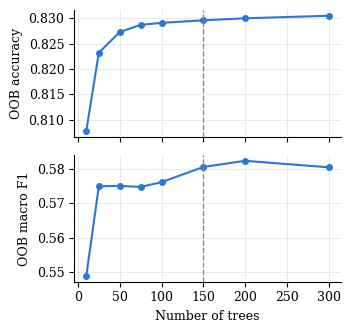

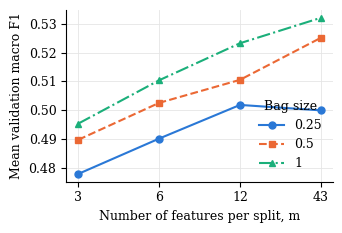

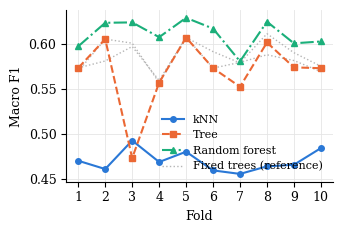

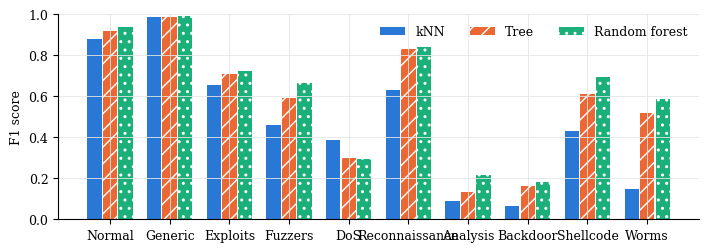

In [ ]:
import matplotlib.pyplot as plt

FIG_PATH = OUT_PATH + 'figures/'
os.makedirs(FIG_PATH, exist_ok=True)
plt.rcParams.update({'font.family': 'serif', 'font.size': 9,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e5e5e5', 'grid.linewidth': 0.6,
                     'lines.linewidth': 1.5, 'legend.frameon': False})
COLW, FULLW = 3.5, 7.16
MODEL_STYLE = {'kNN': ('#2a78d6', 'o', '-', ''),
               'Tree': ('#eb6834', 's', '--', '//'),
               'Random forest': ('#1baf7a', '^', '-.', '..')}
BAG_STYLE = {0.25: ('#2a78d6', 'o', '-'), 0.5: ('#eb6834', 's', '--'), 1.0: ('#1baf7a', '^', '-.')}

# Figure 1: OOB curve (Q1)
fig, axes = plt.subplots(2, 1, figsize=(COLW, 3.4), sharex=True)
for ax, col, label in [(axes[0], 'oob_accuracy', 'OOB accuracy'),
                       (axes[1], 'oob_macro_f1', 'OOB macro F1')]:
    ax.plot(oob_curve['n_trees'], oob_curve[col], color='#2a78d6', marker='o', ms=4)
    ax.axvline(150, color='#8a8a8a', ls='--', lw=1)
    ax.set_ylabel(label)
axes[1].set_xlabel('Number of trees')
fig.tight_layout()
fig.savefig(FIG_PATH + 'oob_curve.pdf', bbox_inches='tight')
plt.show()

# Figure 2: validation macro F1 by m, one line per bag size (Q2 and Q3)
grid_mean = tl.pivot_table(index='m', columns='bag', values='val_macro_f1', aggfunc='mean')
x = np.arange(len(grid_mean.index))
fig, ax = plt.subplots(figsize=(COLW, 2.4))
for b in grid_mean.columns:
    c, mk, ls = BAG_STYLE[b]
    ax.plot(x, grid_mean[b], color=c, marker=mk, ls=ls, ms=5, label=f"{b:g}")
ax.set_xticks(x)
ax.set_xticklabels([str(m) for m in grid_mean.index])
ax.set_xlabel('Number of features per split, m')
ax.set_ylabel('Mean validation macro F1')
ax.legend(title='Bag size', loc='lower right')
fig.tight_layout()
fig.savefig(FIG_PATH + 'm_and_bag_size.pdf', bbox_inches='tight')
plt.show()

# Figure 3: macro F1 per fold, fixed trees as grey reference
fig, ax = plt.subplots(figsize=(COLW, 2.4))
folds = np.arange(1, N_FOLDS + 1)
for label in ['Tree fixed (None, 5)', 'Tree fixed (20, 1)']:
    ref = fixed_ref[fixed_ref['model'] == label].sort_values('fold')['macro_f1']
    ax.plot(folds, ref, color='#b5b5b5', lw=1, ls=':')
for name, res in model_results.items():
    c, mk, ls, _ = MODEL_STYLE[name]
    ax.plot(folds, res['macro_f1'], color=c, marker=mk, ls=ls, ms=4, label=name)
ax.plot([], [], color='#b5b5b5', lw=1, ls=':', label='Fixed trees (reference)')
ax.set_xticks(folds)
ax.set_xlabel('Fold')
ax.set_ylabel('Macro F1')
ax.legend(loc='lower right', fontsize=8)
fig.tight_layout()
fig.savefig(FIG_PATH + 'macro_f1_per_fold.pdf', bbox_inches='tight')
plt.show()

# Figure 4: per class F1 (Q4), full width
order = class_summary['name'].tolist()
xc = np.arange(len(order))
w = 0.26
fig, ax = plt.subplots(figsize=(FULLW, 2.6))
for i, name in enumerate(['kNN', 'Tree', 'Random forest']):
    c, _, _, hatch = MODEL_STYLE[name]
    ax.bar(xc + (i - 1) * w, f1_table.loc[order, name], width=w - 0.02, color=c,
           hatch=hatch, edgecolor='white', linewidth=0, label=name)
ax.set_xticks(xc)
ax.set_xticklabels(order)
ax.set_ylabel('F1 score')
ax.set_ylim(0, 1)
ax.legend(ncol=3, loc='upper right')
fig.tight_layout()
fig.savefig(FIG_PATH + 'per_class_f1.pdf', bbox_inches='tight')
plt.show()